# Clase 14 · Cómo se arma un índice compuesto: el mercado de trabajo en los aglomerados de la EPH
**Ciencia de Datos para Economía y Negocios - FCE-UBA**

Este notebook está pensado para **leerlo y correrlo por tu cuenta**, celda por celda (en Jupyter o Colab, Shift+Enter; en RStudio, Ctrl+Shift+Enter dentro de cada chunk). Cada bloque de código tiene antes un texto que explica qué hace y por qué, y después una caja 💡 que explica cómo leer el resultado.

**La pregunta**: ¿en qué aglomerados urbanos de la Argentina el mercado de trabajo funciona mejor y en cuáles peor? Para responderla no alcanza con una sola variable. La desocupación no dice nada sobre la informalidad, la informalidad no dice nada sobre los salarios y los salarios no dicen nada sobre cuántas horas se trabaja. Vamos a construir un **índice compuesto**: un único número por aglomerado que resume varias dimensiones del mercado de trabajo.

El objetivo no es solo llegar al número. Es ver que, en el camino, hay que tomar **muchas decisiones** (qué variables entran, cómo se transforman, cómo se llevan a una escala común, cuánto pesa cada una y cómo se combinan) y que cada decisión cambia el resultado. Al final vamos a discutir una pregunta incómoda: **¿cómo sabemos si el índice está "bien"?**

| Parte | Qué se ve |
|:--|:--|
| 1 | Qué es un índice compuesto y cuáles son las decisiones que hay que tomar |
| 2 | El marco conceptual del caso: dimensiones, variables y direcciones |
| 3 | De los microdatos de la EPH a los indicadores por aglomerado |
| 4 | Mirar las variables antes de calcular: distribuciones y correlaciones |
| 5 | Transformar las variables |
| 6 | Normalizar: llevar todo a una escala común |
| 7 | Ponderar: cuánto pesa cada dimensión |
| 8 | Agregar: cómo se combinan las dimensiones |
| 9 | El índice base y cómo se lee |
| 10 | Análisis de sensibilidad: cuánto depende el resultado de las decisiones |
| 11 | Validación: qué se puede validar y qué no |
| Cierre | Conclusiones y checklist para el TP |

La primera vez hace falta internet: se instalan los paquetes y se bajan los datos, que quedan guardados en `datos_clase14/`.

**En Google Colab**: Entorno de ejecución → Cambiar tipo de entorno de ejecución → **R**.

In [1]:
# Paquetes: instala solo los que faltan (en Colab tarda unos minutos la primera vez)
paquetes <- c("tidyverse", "eph")
faltan <- setdiff(paquetes, rownames(installed.packages()))
if (length(faltan) > 0) install.packages(faltan)

suppressWarnings(suppressPackageStartupMessages({
  library(tidyverse)
}))
# Del paquete eph usamos solo dos funciones y las llamamos con eph::

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 110)   # tamaño de gráficos en Jupyter
theme_set(theme_minimal(base_size = 13))

### Datos

Usamos dos bases de la **Encuesta Permanente de Hogares** (EPH, INDEC): la de **personas** y la de **hogares**, de los cuatro trimestres que van del 2º trimestre de 2025 al 1º de 2026. ¿Por qué cuatro trimestres y no uno? Porque vamos a calcular proporciones por aglomerado (por ejemplo, el porcentaje de asalariados sin descuento jubilatorio) y en los aglomerados chicos un solo trimestre tiene pocos casos: las proporciones saltan mucho de un trimestre a otro por pura casualidad de la muestra. Juntar cuatro trimestres (un *pool*) multiplica los casos por cuatro y estabiliza las estimaciones.

También usamos las **canastas básicas regionales** del INDEC, que publica el paquete `eph`, para ajustar los ingresos por las diferencias de precios entre regiones (lo explicamos en la Parte 3).

La función `con_cache()` baja los datos la primera vez y los guarda en `datos_clase14/`, solo con las columnas que usamos. Las veces siguientes los lee de ahí, sin internet.

In [2]:
carpeta_datos <- "datos_clase14"
dir.create(carpeta_datos, showWarnings = FALSE)

con_cache <- function(nombre, crear) {
  archivo <- file.path(carpeta_datos, paste0(nombre, ".rds"))
  if (!file.exists(archivo)) saveRDS(crear(), archivo)
  readRDS(archivo)
}

trimestres <- tibble(anio = c(2025, 2025, 2025, 2026), trimestre = c(2, 3, 4, 1))

vars_personas <- c("ANO4", "TRIMESTRE", "REGION", "AGLOMERADO", "PONDERA", "PONDIIO",
                   "ESTADO", "CAT_OCUP", "INTENSI", "PP07C", "PP07G4", "PP07H",
                   "PP3E_TOT", "P21")
vars_hogares  <- c("ANO4", "TRIMESTRE", "REGION", "AGLOMERADO", "PONDERA", "PONDIH",
                   "V5_01", "V5_02", "V5_03", "IPCF")

# Baja los cuatro trimestres de una base y los apila
bajar_eph <- function(tipo, vars) {
  map2(trimestres$anio, trimestres$trimestre, \(a, t)
       eph::get_microdata(year = a, period = t, type = tipo, vars = vars) |>
         select(all_of(vars)) |>
         mutate(across(everything(), as.numeric))) |>
    list_rbind()
}

personas <- con_cache("eph_personas", \() bajar_eph("individual", vars_personas))
hogares  <- con_cache("eph_hogares",  \() bajar_eph("hogar", vars_hogares))
canastas <- con_cache("canastas_regionales", \() eph::get_poverty_lines(regional = TRUE) |> ungroup())

count(personas, ANO4, TRIMESTRE)

ANO4,TRIMESTRE,n
<dbl>,<dbl>,<int>
2025,2,46086
2025,3,44946
2025,4,43703
2026,1,43739


> ⚠️ **Atención (Colab).** A veces el servidor del INDEC no acepta descargas desde las máquinas de Google y esta celda falla. En ese caso: (1) bajá los archivos `eph_personas.rds`, `eph_hogares.rds` y `canastas_regionales.rds` que comparte la cátedra; (2) en Colab, abrí el panel de archivos (ícono de carpeta, a la izquierda), creá una carpeta `datos_clase14` y subí ahí los archivos; (3) volvé a correr la celda. Como los archivos ya existen, `con_cache()` los lee y no intenta bajar nada.

# Parte 1. Qué es un índice compuesto

## 1.1 Medir algo que no se observa

Hay conceptos que usamos todo el tiempo y que **no se pueden observar directamente**: el desarrollo de un país, la competitividad de una economía, la calidad de una democracia o, en nuestro caso, el *funcionamiento del mercado de trabajo*. No hay una encuesta que pregunte "¿qué tan bien funciona el mercado de trabajo de Rosario?". Lo que sí hay son variables observables que capturan **aspectos parciales** del concepto: la tasa de desocupación, el porcentaje de informales, los salarios.

Un **índice compuesto** combina esas variables parciales en un único número. El ejemplo más conocido es el **Índice de Desarrollo Humano** (IDH) del PNUD, que combina esperanza de vida, educación e ingreso. La construcción va siempre en el mismo sentido:

$$\text{concepto} \;\longrightarrow\; \text{dimensiones} \;\longrightarrow\; \text{variables (indicadores)} \;\longrightarrow\; \text{índice}$$

El manual de referencia es el de la **OCDE y el JRC** de la Comisión Europea (Nardo et al., 2008), que ordena el proceso en diez pasos. El primero, y el que más se saltea, es el **marco teórico**: sin una idea clara de qué se quiere medir no hay forma de decidir qué variables entran, cuáles quedan afuera ni con qué signo.

## 1.2 Las cinco decisiones

Una vez que se tienen las variables, todo índice compuesto exige cinco decisiones técnicas. Las vamos a recorrer en orden:

| Decisión | Pregunta | Ejemplo en el IDH |
|:--|:--|:--|
| **Selección** | ¿Qué variables entran y en qué dimensión? | Esperanza de vida, años de escolaridad, ingreso |
| **Transformación** | ¿Hay que cambiar la forma de alguna variable antes de usarla? | El ingreso entra en logaritmo |
| **Normalización** | ¿Cómo se llevan variables en distintas unidades a una escala común? | Cada variable se lleva a 0-1 con umbrales fijos |
| **Ponderación** | ¿Cuánto pesa cada dimensión? | Un tercio cada una |
| **Agregación** | ¿Cómo se combinan? ¿Se suman, se multiplican? | Media geométrica |

La idea central de este notebook es que **ninguna de estas decisiones es neutral**. Parecen técnicas, pero cada una incorpora un juicio de valor: cuánto importa una cosa respecto de otra, cuánto se acepta que un buen resultado en una dimensión compense uno malo en otra. Por eso un índice compuesto bien hecho **explicita** cada decisión y **muestra cuánto cambia** el resultado si se hubiera decidido otra cosa (el *análisis de sensibilidad*).

## 1.3 Indicadores reflectivos y formativos

Una distinción que ordena varias decisiones posteriores:

- **Modelo reflectivo**: las variables son *manifestaciones* de un mismo concepto latente. Los ítems de una prueba de comprensión lectora son reflectivos: si alguien comprende bien, contesta bien todos. En este modelo se espera que las variables estén **muy correlacionadas** entre sí, y si una no correlaciona con las demás, probablemente mide otra cosa.
- **Modelo formativo**: las variables *construyen* el concepto y pueden ser independientes entre sí. El mercado de trabajo es formativo: un aglomerado puede tener poca desocupación y mucha informalidad a la vez, y las dos cosas son parte de cómo funciona su mercado laboral. En este modelo una correlación baja entre variables **no es un problema**: es justamente lo que justifica incluir las dos. Lo que hay que vigilar es lo contrario, la **redundancia**: dos variables que dicen lo mismo y que, si entran las dos, hacen pesar doble a ese aspecto.

Nuestro índice es **formativo**. Lo vamos a tener en cuenta al elegir los pesos (Parte 7) y al pensar la validación (Parte 11).

# Parte 2. El marco conceptual del caso

## 2.1 Qué es un "buen" mercado de trabajo

Partimos de la noción de **trabajo decente** de la Organización Internacional del Trabajo (OIT): un mercado de trabajo funciona bien si quien quiere trabajar consigue empleo, y si ese empleo paga un ingreso suficiente, tiene protección social, es estable y tiene una jornada adecuada. De ahí salen cinco dimensiones:

| Dimensión | Pregunta | Variable | Denominador | Dirección |
|:--|:--|:--|:--|:--:|
| **Acceso** | ¿Quien quiere trabajar consigue empleo? | Tasa de desocupación | Población económicamente activa (PEA) | $-$ |
| | ¿Qué parte de la población trabaja? | Tasa de empleo | Población total | $+$ |
| **Ingresos** | ¿Cuánto paga una hora de trabajo? | Ingreso horario mediano de la ocupación principal (relativo y ajustado por región) | Ocupados con ingreso | $+$ |
| **Protección** | ¿El empleo asalariado está registrado? | % de asalariados sin descuento jubilatorio | Asalariados | $-$ |
| | ¿Tiene cobertura de salud? | % de asalariados sin obra social | Asalariados | $-$ |
| **Estabilidad** | ¿El empleo tiene fecha de finalización? | % de asalariados con empleo temporario | Asalariados | $-$ |
| **Tiempo de trabajo** | ¿Se trabajan menos horas de las que se quiere? | Tasa de subocupación horaria | PEA | $-$ |
| | ¿Se trabajan jornadas excesivas? | % de ocupados con más de 45 horas semanales | Ocupados | $-$ |

La columna **dirección** dice si un valor más alto de la variable es mejor ($+$) o peor ($-$) para el concepto. La mayoría de las variables son "malas": más desocupación o más informalidad es peor. Más adelante vamos a tener que dar vuelta su signo para que en el índice "más alto" siempre signifique "mejor".

La columna **denominador** sigue las convenciones del INDEC y no es un detalle. La desocupación se calcula sobre la PEA (ocupados más desocupados), no sobre la población total, porque mide qué parte de **quienes buscan trabajo** no lo consigue. Las preguntas sobre descuento jubilatorio, obra social y duración del empleo se les hacen **solo a los asalariados** (a un cuentapropista no se le puede preguntar si su empleador le hace aportes), así que esas proporciones tienen a los asalariados como denominador. Es decir: **cada indicador mira a la población para la que la pregunta tiene sentido**.

## 2.2 Qué dice cada variable y qué queda afuera

Antes de calcular nada conviene hacerse, para cada variable, cuatro preguntas: qué fenómeno captura, en qué dirección se relaciona con el concepto, si mide un insumo o un resultado, y **qué agrega que las otras no tengan**. Dos casos para pensar:

- **¿Por qué dos variables de protección?** El descuento jubilatorio es la definición estándar de informalidad asalariada. La obra social, en la Argentina, viene casi siempre con el registro. Sospechamos que dicen casi lo mismo. Las dejamos a propósito para ver qué pasa con una variable **redundante** (Partes 4 y 7).
- **¿Por qué no está la tasa de actividad?** La tasa de actividad (PEA sobre población) es una de las tres tasas clásicas, pero su **dirección es ambigua**. Puede subir porque mejoran las oportunidades y más gente sale a buscar trabajo (bueno), o porque cae el ingreso del hogar y otros miembros salen a trabajar para compensar, el efecto del *trabajador adicional* (malo). Si no se puede decir si "más" es mejor o peor, la variable no puede entrar en un índice con un signo fijo. Dejarla afuera **también es una decisión**, y hay que escribirla.

> ⚠️ **Atención.** La sobreocupación también tiene una dirección discutible: trabajar más de 45 horas puede ser una elección para ganar más. La incluimos con signo negativo porque, en el marco de trabajo decente, las jornadas excesivas son un déficit (y porque en los datos va junto con la informalidad, como vamos a ver). En un TP, una variable con dirección discutible necesita un párrafo que la justifique.

# Parte 3. De los microdatos a los indicadores

Cada fila de la base `personas` es una persona encuestada en un trimestre. Nuestra unidad de análisis es el **aglomerado** (hay 32), así que tenemos que pasar de personas a tasas por aglomerado. Las tasas se calculan **ponderadas**: cada persona representa a tantas personas de la población como dice su ponderador. Para tasas de empleo se usa `PONDERA`; para ingresos, `PONDIIO`, que el INDEC corrige por la no respuesta de ingresos.

Las variables de la EPH que usamos:

| Variable | Qué es |
|:--|:--|
| `ESTADO` | Condición de actividad: 1 ocupado, 2 desocupado, 3 inactivo, 4 menor de 10 años |
| `CAT_OCUP` | Categoría ocupacional: 3 es obrero o empleado (asalariado) |
| `INTENSI` | Intensidad de la ocupación: 1 subocupado horario, 2 ocupado pleno, 3 sobreocupado (más de 45 horas), 4 no trabajó en la semana |
| `PP07H` | ¿Por ese trabajo tiene descuento jubilatorio? 1 sí, 2 no |
| `PP07G4` | ¿Tiene obra social? 1 sí, 2 no |
| `PP07C` | ¿Ese empleo tiene tiempo de finalización? 1 sí, 2 no |
| `P21` | Ingreso mensual de la ocupación principal |
| `PP3E_TOT` | Horas semanales trabajadas en la ocupación principal |

## 3.1 Las tasas

La suma ponderada de una condición dividida por la suma ponderada del denominador es una proporción poblacional. Por ejemplo, la tasa de desocupación es

$$\text{desocupación}_a = \frac{\sum_{i \in a} w_i \cdot \mathbb{1}[\text{desocupado}_i]}{\sum_{i \in a} w_i \cdot \mathbb{1}[\text{activo}_i]}$$

donde $w_i$ es el ponderador y $\mathbb{1}[\cdot]$ vale 1 si se cumple la condición. En R, `sum(PONDERA * (ESTADO == 2))` hace exactamente el numerador: `ESTADO == 2` es `TRUE` (1) o `FALSE` (0).

In [3]:
tasas <- personas |>
  mutate(activo     = ESTADO %in% 1:2,
         ocupado    = ESTADO == 1,
         asalariado = ESTADO == 1 & CAT_OCUP == 3) |>
  group_by(AGLOMERADO, REGION) |>
  summarise(
    desocupacion = sum(PONDERA * (ESTADO == 2)) / sum(PONDERA * activo),
    empleo       = sum(PONDERA * ocupado) / sum(PONDERA),
    subocupacion = sum(PONDERA * (ocupado & INTENSI %in% 1)) / sum(PONDERA * activo),
    sobreocup    = sum(PONDERA * (ocupado & INTENSI %in% 3)) / sum(PONDERA * ocupado),
    # Para las preguntas de asalariados, el denominador son quienes contestaron sí o no
    sin_descuento  = sum(PONDERA * (asalariado & PP07H %in% 2)) / sum(PONDERA * (asalariado & PP07H %in% 1:2)),
    sin_obra_soc   = sum(PONDERA * (asalariado & PP07G4 %in% 2)) / sum(PONDERA * (asalariado & PP07G4 %in% 1:2)),
    temporario     = sum(PONDERA * (asalariado & PP07C %in% 1)) / sum(PONDERA * (asalariado & PP07C %in% 1:2)),
    n_activos      = sum(activo),
    n_asalariados  = sum(asalariado),
    .groups = "drop")

tasas |> select(AGLOMERADO, desocupacion:temporario) |> head()

AGLOMERADO,desocupacion,empleo,subocupacion,sobreocup,sin_descuento,sin_obra_soc,temporario
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2,0.08102722,0.4545161,0.15489530,0.2697471,0.3437319,0.3336325,0.09753040
3,0.07875502,0.4374535,0.10292695,0.2617469,0.2844795,0.2387207,0.07422026
4,0.07817493,0.4854078,0.10356751,0.2464428,0.3565575,0.3297726,0.10498732
5,0.05754712,0.4201786,0.08878078,0.2358734,0.3209110,0.2628415,0.05346307
6,0.05276597,0.4364457,0.13833214,0.2474072,0.2791856,0.2559008,0.09387479
7,0.04299094,0.4434142,0.08735286,0.3408256,0.4205276,0.4036582,0.04818266


## 3.2 El ingreso: dos transformaciones antes de empezar

El ingreso trae dos problemas que hay que resolver antes de compararlo entre aglomerados.

**Problema 1: la inflación.** Juntamos cuatro trimestres y entre el primero y el último los precios subieron bastante. Un ingreso de 2025 y uno de 2026 no se pueden promediar en pesos corrientes. En vez de deflactar con el índice de precios (otra descarga, otra decisión), usamos un truco más simple: **dividimos cada ingreso horario por la mediana nacional de su propio trimestre**. Así cada ingreso queda expresado como "cuántas veces la mediana del país en ese momento". Un valor de 1,2 significa que esa hora de trabajo paga un 20% más que la hora mediana del país. La inflación desaparece porque afecta al numerador y al denominador por igual.

**Problema 2: los precios regionales.** Con el mismo salario se compran cosas distintas en Ushuaia y en Santiago del Estero. Si no lo corregimos, los aglomerados patagónicos van a aparecer arriba en ingresos en parte porque **todo es más caro** ahí. El INDEC calcula una canasta básica total (CBT) para cada región. Usamos el cociente entre la CBT de cada región y la del Gran Buenos Aires como **índice de precios regional** y dividimos los ingresos por ese factor.

Las dos son **transformaciones** de la variable. La segunda es discutible (la CBT es una canasta de pobreza, no un índice de precios general) y por eso, en el análisis de sensibilidad, vamos a ver qué pasa si no se hace.

In [4]:
# Factor de precios regional: CBT de la región / CBT del GBA, promedio de los últimos 4 períodos publicados
factor_regional <- canastas |>
  filter(periodo %in% tail(sort(unique(periodo)), 4)) |>
  group_by(periodo) |>
  mutate(factor = CBT / CBT[region == "GBA"]) |>
  group_by(REGION = codigo, region) |>
  summarise(factor = mean(factor), .groups = "drop")

factor_regional

REGION,region,factor
<dbl>,<chr>,<dbl>
1,GBA,1.0000000
40,Noroeste,0.8034457
41,Noreste,0.8323264
42,Cuyo,0.9484759
43,Pampeana,0.9866214
44,Patagonia,1.1664566


> 💡 **Lectura.** La canasta de la Patagonia es un 17% más cara que la del GBA, y la del Noroeste un 20% más barata. Por eso un ingreso de Ushuaia se divide por 1,17 (baja) y uno de Salta por 0,80 (sube): con el mismo número de pesos, en Salta se compran más cosas. Fijate que el ajuste es **por región**, no por aglomerado: todos los aglomerados del Noroeste reciben el mismo factor.

Ahora calculamos el ingreso horario de cada ocupado y lo resumimos por aglomerado con la **mediana ponderada**. Usamos la mediana y no la media porque el ingreso tiene una cola derecha larga: unos pocos ingresos muy altos mueven mucho la media (lo vemos en la Parte 5). La función `mediana_ponderada()` ordena los valores y busca el primero en el que el peso acumulado llega a la mitad del total.

In [1]:
mediana_ponderada <- function(x, w) {
  orden <- order(x)
  x <- x[orden]
  w_acum <- cumsum(w[orden])
  x[which(w_acum >= w_acum[length(w_acum)] / 2)[1]]
}

ingresos_personas <- personas |>
  filter(ESTADO == 1, P21 > 0, PP3E_TOT > 0, PP3E_TOT < 999, PONDIIO > 0) |>   # 999 = sin dato de horas
  mutate(ingreso_horario = P21 / (PP3E_TOT * 30 / 7)) |>                      # horas semanales -> mensuales
  group_by(ANO4, TRIMESTRE) |>
  mutate(ingreso_rel = ingreso_horario / mediana_ponderada(ingreso_horario, PONDIIO)) |>
  ungroup() |>
  left_join(factor_regional, by = "REGION") |>
  mutate(ingreso_rel_reg = ingreso_rel / factor)

ingresos <- ingresos_personas |>
  group_by(AGLOMERADO) |>
  summarise(ingreso_sin_ajuste = mediana_ponderada(ingreso_rel, PONDIIO),
            ingreso            = mediana_ponderada(ingreso_rel_reg, PONDIIO),
            n_ingresos         = n())

ERROR: Error in mutate(left_join(ungroup(mutate(group_by(mutate(filter(personas, : could not find function "mutate"


## 3.3 La tabla de indicadores

Juntamos todo en una tabla con **una fila por aglomerado y una columna por variable**. Esta es la materia prima de cualquier índice compuesto, y es lo primero que tienen que armar en el TP. Agregamos el nombre de cada aglomerado, que viene en el paquete `eph`.

In [6]:
nombres <- eph::diccionario_aglomerados |>
  transmute(AGLOMERADO = codigo, aglomerado = aglo)

ind <- tasas |>
  left_join(ingresos, by = "AGLOMERADO") |>
  left_join(nombres, by = "AGLOMERADO") |>
  relocate(aglomerado, .after = AGLOMERADO)

ind |>
  select(aglomerado, desocupacion, empleo, ingreso, sin_descuento, sin_obra_soc,
         temporario, subocupacion, sobreocup) |>
  mutate(across(where(is.numeric), \(x) round(x, 3))) |>
  arrange(aglomerado)

aglomerado,desocupacion,empleo,ingreso,sin_descuento,sin_obra_soc,temporario,subocupacion,sobreocup
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Bahía Blanca - Cerri,0.079,0.437,1.126,0.284,0.239,0.074,0.103,0.262
Cdro. Rivadavia - R. Tilly,0.030,0.394,1.072,0.206,0.185,0.017,0.041,0.356
Ciudad de Bs. As.,0.044,0.523,1.500,0.255,0.230,0.069,0.080,0.202
Concordia,0.056,0.392,0.811,0.480,0.452,0.206,0.096,0.363
Corrientes,0.064,0.400,0.865,0.419,0.394,0.198,0.071,0.345
Formosa,0.050,0.388,0.881,0.407,0.387,0.037,0.037,0.382
Gran Catamarca,0.049,0.431,0.968,0.418,0.411,0.100,0.129,0.271
Gran Córdoba,0.085,0.468,1.027,0.422,0.408,0.181,0.147,0.250
Gran La Plata,0.081,0.455,0.965,0.344,0.334,0.098,0.155,0.270


> 💡 **Lectura.** Cada fila es un aglomerado y cada columna, una variable. Las diferencias son grandes: la desocupación va del 1,1% (Viedma) al 9,5% (Gran Resistencia), y el porcentaje de asalariados sin descuento jubilatorio, del 16% (Ushuaia) al 52% (Gran San Juan). El ingreso está en "veces la mediana nacional": en la Ciudad de Buenos Aires la hora mediana paga 1,5 veces la del país, y en Gran San Juan, 0,76 veces. El ajuste regional se nota en los extremos. Neuquén pasa de 1,43 sin ajuste a 1,22 con ajuste, y Gran Tucumán de 0,83 a 1,04.

In [7]:
summarise(ind, across(c(n_activos, n_asalariados, n_ingresos), list(min = min, mediana = median)))

n_activos_min,n_activos_mediana,n_asalariados_min,n_asalariados_mediana,n_ingresos_min,n_ingresos_mediana
<int>,<dbl>,<int>,<dbl>,<int>,<dbl>
1225,2334.5,912,1578.5,789,1658.5


> 💡 **Lectura.** El aglomerado más chico tiene 1.225 activos y 912 asalariados en la muestra de los cuatro trimestres. Con un solo trimestre serían unos 230 asalariados, y una proporción del 30% tendría un margen de error de al menos ±6 puntos ($1{,}96 \sqrt{0{,}3 \cdot 0{,}7 / 230}$). Con el *pool*, el margen baja a unos ±3 puntos. Igual, conviene recordar que **cada número de la tabla es una estimación con error muestral**: diferencias de uno o dos puntos entre aglomerados pueden ser ruido.

> ⚠️ **Atención: datos faltantes.** En este caso los 32 aglomerados tienen dato en las ocho variables, así que no hay que decidir qué hacer con los faltantes. En muchos TP no va a ser así. Las opciones son eliminar la unidad, imputar (por ejemplo, con el promedio de su región) o calcular el índice con las variables disponibles (que equivale a repartir el peso de la que falta entre las otras). Las tres cambian el resultado, y hay que informarlas.

# Parte 4. Mirar las variables antes de calcular

## 4.1 Distribuciones

Antes de combinar variables conviene mirar cómo se distribuye cada una entre los aglomerados: en qué rango se mueven, si hay valores extremos, si están concentradas.

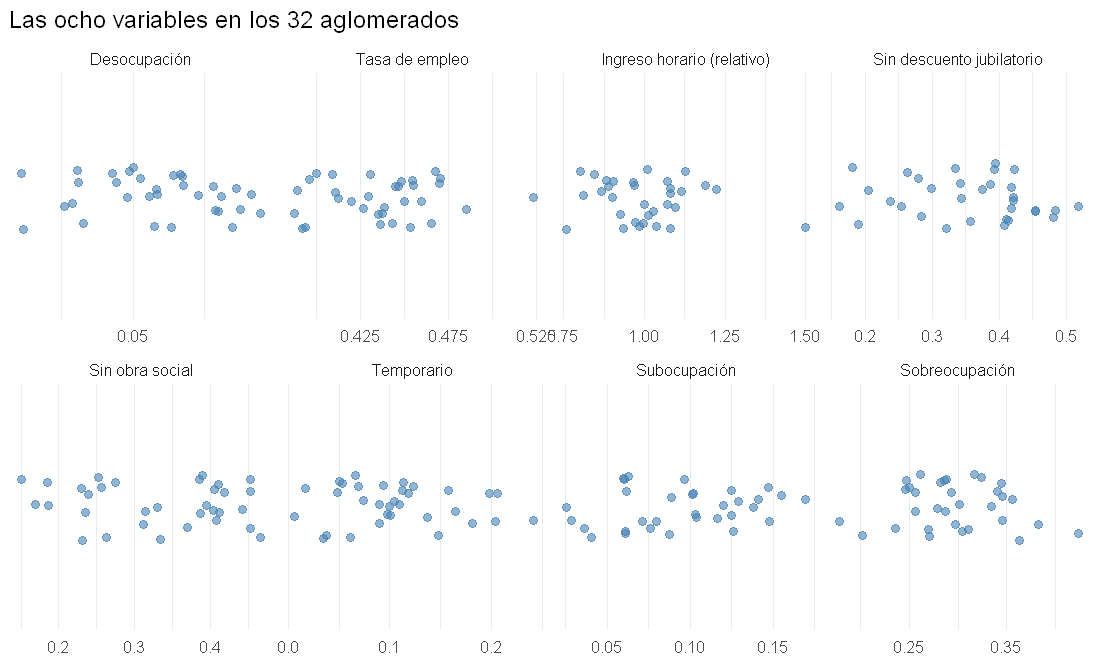

In [8]:
options(repr.plot.height = 6.05)
etiquetas <- c(desocupacion = "Desocupación", empleo = "Tasa de empleo",
               ingreso = "Ingreso horario (relativo)", sin_descuento = "Sin descuento jubilatorio",
               sin_obra_soc = "Sin obra social", temporario = "Temporario",
               subocupacion = "Subocupación", sobreocup = "Sobreocupación")
variables <- names(etiquetas)

ind |>
  pivot_longer(all_of(variables), names_to = "variable", values_to = "valor") |>
  mutate(variable = factor(variable, levels = variables, labels = etiquetas)) |>
  ggplot(aes(valor, 0)) +
  geom_jitter(height = 0.15, width = 0, alpha = 0.6, size = 2.5, color = "steelblue") +
  facet_wrap(~ variable, scales = "free_x", ncol = 4) +
  scale_x_continuous(n.breaks = 4) +
  scale_y_continuous(NULL, breaks = NULL, limits = c(-0.5, 0.5)) +
  labs(title = "Las ocho variables en los 32 aglomerados", x = NULL)

> 💡 **Lectura.** Ninguna variable tiene un aglomerado muy separado del resto, salvo el ingreso, donde la Ciudad de Buenos Aires (1,5) queda bastante a la derecha. Lo que más llama la atención es que los **rangos son muy distintos**: la desocupación se mueve entre el 1% y el 9%, y la sobreocupación entre el 18% y el 42%. Si sumáramos las variables así, las de rango más amplio dominarían el índice. Por eso hay que normalizar (Parte 6).

## 4.2 Correlaciones: ¿qué aporta cada variable?

La matriz de correlaciones responde la pregunta "qué agrega esta variable que las otras no tengan". Para que se lea más fácil, primero ponemos todas las variables en la dirección "más es mejor" (multiplicamos por $-1$ las de dirección negativa). Así, una correlación positiva significa que las dos variables "están de acuerdo" sobre qué aglomerados están mejor.

In [9]:
direccion <- c(desocupacion = -1, empleo = 1, ingreso = 1, sin_descuento = -1,
               sin_obra_soc = -1, temporario = -1, subocupacion = -1, sobreocup = -1)

ind |>
  transmute(across(all_of(variables), \(x) x * direccion[cur_column()])) |>
  cor() |>
  round(2)

,desocupacion,empleo,ingreso,sin_descuento,sin_obra_soc,temporario,subocupacion,sobreocup
desocupacion,1.00,-0.14,-0.08,-0.07,-0.02,0.14,0.35,-0.22
empleo,-0.14,1.00,0.51,0.03,0.03,-0.11,-0.41,0.48
ingreso,-0.08,0.51,1.00,0.68,0.64,0.32,0.05,0.40
sin_descuento,-0.07,0.03,0.68,1.00,0.96,0.35,0.35,0.26
sin_obra_soc,-0.02,0.03,0.64,0.96,1.00,0.29,0.34,0.27
temporario,0.14,-0.11,0.32,0.35,0.29,1.00,0.36,-0.26
subocupacion,0.35,-0.41,0.05,0.35,0.34,0.36,1.00,-0.36
sobreocup,-0.22,0.48,0.40,0.26,0.27,-0.26,-0.36,1.00


> 💡 **Lectura.** Tres cosas para mirar.
>
> 1. **Redundancia.** Sin descuento jubilatorio y sin obra social correlacionan 0,96: son prácticamente la misma variable. Si las dos entran con el mismo peso que las demás, la protección cuenta doble.
> 2. **Variables que no acompañan.** La desocupación casi no correlaciona con nada (entre −0,22 y 0,35). Hay aglomerados del norte, como Santiago del Estero o Jujuy, con muy poca desocupación y mucha informalidad. La tasa de empleo correlaciona negativamente con la subocupación (−0,41): donde más gente trabaja, más gente trabaja menos horas de las que quisiera.
> 3. **Lo que va junto.** El ingreso correlaciona 0,68 con la protección: donde hay más empleo registrado, la hora se paga mejor.
>
> En un índice **formativo** las correlaciones bajas o negativas no son un problema: muestran que las dimensiones miden cosas distintas, que es justamente por qué las combinamos. Pero también muestran que hay **trade-offs**: un aglomerado puede estar bien en una dimensión y mal en otra, y la forma de agregar va a definir cuánto se compensan.

# Parte 5. Transformar las variables

**Transformar** es cambiar la forma de una variable antes de usarla: aplicarle una función (logaritmo, raíz, recorte de extremos) que modifica las distancias entre los valores. Las tres transformaciones típicas en un índice:

1. **Cambiar la dirección**, para que todas las variables apunten hacia "mejor". Lo hacemos dentro de la normalización (Parte 6).
2. **Logaritmo** para variables muy asimétricas o cuando importan las diferencias **proporcionales** y no las absolutas.
3. **Recortar extremos** (winsorizar) cuando un valor atípico aplastaría la escala del resto. Acá no hace falta: ningún aglomerado está muy separado del resto en ninguna variable.

## 5.1 El logaritmo del ingreso

Miremos el ingreso horario a nivel **persona** (no aglomerado). En niveles tiene una cola derecha muy larga: la mayoría gana cerca de la mediana y unos pocos ganan muchas veces más. En logaritmo, la distribución se vuelve aproximadamente simétrica.

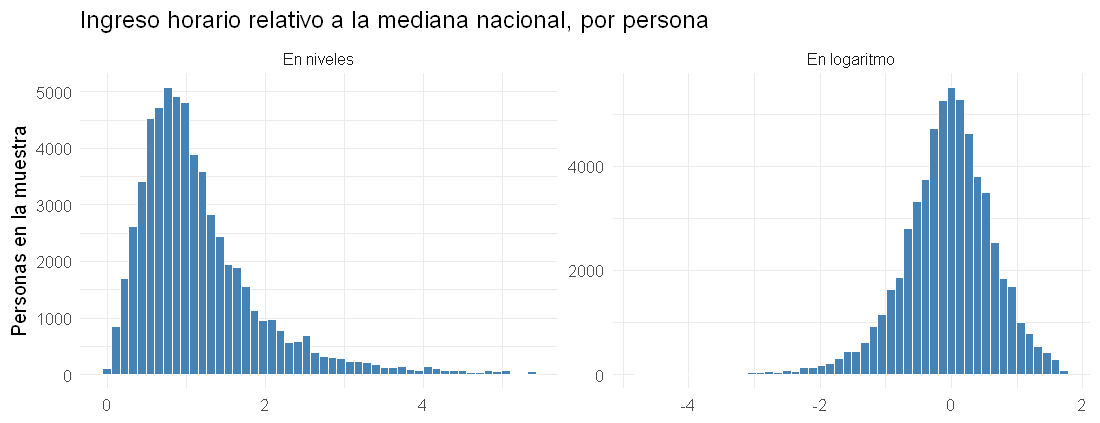

In [10]:
options(repr.plot.height = 3.85)
ingresos_personas |>
  filter(ingreso_rel_reg < quantile(ingreso_rel_reg, 0.99)) |>    # sacamos el 1% más alto solo para ver el gráfico
  mutate(log_ingreso = log(ingreso_rel_reg)) |>
  pivot_longer(c(ingreso_rel_reg, log_ingreso), names_to = "escala") |>
  mutate(escala = factor(escala, labels = c("En niveles", "En logaritmo"))) |>
  ggplot(aes(value)) +
  geom_histogram(bins = 50, fill = "steelblue", color = "white") +
  facet_wrap(~ escala, scales = "free") +
  labs(title = "Ingreso horario relativo a la mediana nacional, por persona",
       x = NULL, y = "Personas en la muestra")

A nivel aglomerado ya resumimos con la **mediana**, que no se ve afectada por la cola. ¿Hace falta igual el logaritmo? Sí, por otra razón: nuestro indicador es un **cociente** (ingreso del aglomerado sobre la mediana nacional), y los cocientes son asimétricos en niveles. Un aglomerado que gana la mitad de la mediana (0,5) está a 0,5 de distancia de la mediana; uno que gana el doble (2) está a 1 de distancia. Pero las dos son la misma distancia **proporcional**. En logaritmo, $\log(0{,}5) = -0{,}69$ y $\log(2) = +0{,}69$: quedan a la misma distancia del cero. Esto expresa una idea que también usa el IDH: **un peso más vale más para quien gana poco que para quien gana mucho** (rendimientos decrecientes).

In [11]:
ind <- ind |>
  mutate(log_ingreso = log(ingreso),
         log_ingreso_sin_ajuste = log(ingreso_sin_ajuste))

# Desde ahora, la variable de ingresos del índice es log_ingreso
variables <- c("desocupacion", "empleo", "log_ingreso", "sin_descuento",
               "sin_obra_soc", "temporario", "subocupacion", "sobreocup")
names(direccion)[names(direccion) == "ingreso"] <- "log_ingreso"
etiquetas <- setNames(etiquetas, variables)

> ⚠️ **Atención.** Transformar no es "mejorar los datos": es decidir qué diferencias importan. Con el logaritmo, pasar de 0,7 a 0,8 veces la mediana suma más al índice que pasar de 1,4 a 1,5. Si el marco conceptual dijera que cada peso cuenta igual sin importar el nivel, el logaritmo estaría mal.

# Parte 6. Normalizar: llevar todo a una escala común

## 6.1 Por qué hace falta

Las variables están en unidades distintas: la desocupación va de 0,01 a 0,09, el logaritmo del ingreso de $-0{,}28$ a $0{,}41$. Si las sumáramos así, la que tiene más variación dominaría el índice por una cuestión de **unidades**, no de importancia. **Normalizar** es llevar todas a una escala común y, de paso, dar vuelta las de dirección negativa para que "más alto" sea siempre "mejor".

Hay cuatro métodos habituales. Para cada uno, $x_a$ es el valor del aglomerado $a$ y $I_a$ el valor normalizado. Para las variables de dirección negativa, se usa $1 - I_a$ (o $-I_a$ en el z-score).

| Método | Fórmula | Rango | Qué mide |
|:--|:--|:--|:--|
| **Min-max con umbrales fijos** | $\dfrac{x_a - x^{\text{malo}}}{x^{\text{bueno}} - x^{\text{malo}}}$ | 0 a 1 | Dónde está el aglomerado entre un valor "malo" y uno "bueno" fijados de antemano |
| **Min-max observado** | $\dfrac{x_a - \min(x)}{\max(x) - \min(x)}$ | 0 a 1 | Dónde está entre el peor y el mejor aglomerado **de la muestra** |
| **Z-score** | $\dfrac{x_a - \bar{x}}{s_x}$ | sin límites, media 0 | Cuántos desvíos estándar está por encima o por debajo del promedio |
| **Rangos** | $\dfrac{\text{posición}_a}{n}$ | $1/n$ a 1 | Solo el orden: qué lugar ocupa entre los $n$ aglomerados |

Las tres últimas son **relativas a la muestra**: si se agrega o se saca un aglomerado, cambia el valor normalizado de todos los demás aunque nada haya cambiado en ellos. La primera es **absoluta**: el valor de un aglomerado depende solo de sus propios datos y de los umbrales.

## 6.2 Los umbrales fijos

Para la normalización con umbrales fijos hay que elegir, para cada variable, un valor "malo" (que vale 0) y uno "bueno" (que vale 1). Es una decisión **normativa** que se apoya en referencias externas, no en los datos de la muestra. Las nuestras:

In [12]:
umbrales <- tribble(
  ~variable,       ~malo,     ~bueno,  ~justificacion,
  "desocupacion",  0.20,      0,       "20%: el pico de 2002",
  "empleo",        0.30,      0.60,    "Rango de las economías de la región",
  "log_ingreso",   log(0.5),  log(2),  "De la mitad al doble de la mediana nacional",
  "sin_descuento", 0.60,      0,       "60%: más de la mitad de los asalariados en negro",
  "sin_obra_soc",  0.60,      0,       "Igual que el descuento jubilatorio",
  "temporario",    0.30,      0,       "30%: uno de cada tres asalariados con fecha de fin",
  "subocupacion",  0.20,      0,       "20%: el pico de 2002",
  "sobreocup",     0.50,      0,       "La mitad de los ocupados con jornadas largas"
)
umbrales

variable,malo,bueno,justificacion
<chr>,<dbl>,<dbl>,<chr>
desocupacion,0.2000000,0.0000000,20%: el pico de 2002
empleo,0.3000000,0.6000000,Rango de las economías de la región
log_ingreso,-0.6931472,0.6931472,De la mitad al doble de la mediana nacional
sin_descuento,0.6000000,0.0000000,60%: más de la mitad de los asalariados en negro
sin_obra_soc,0.6000000,0.0000000,Igual que el descuento jubilatorio
temporario,0.3000000,0.0000000,30%: uno de cada tres asalariados con fecha de fin
subocupacion,0.2000000,0.0000000,20%: el pico de 2002
sobreocup,0.5000000,0.0000000,La mitad de los ocupados con jornadas largas


Los umbrales están elegidos para que **ningún aglomerado quede afuera del rango** (si quedara, lo recortamos a 0 o a 1). Fijate que en las variables negativas el valor "malo" es más alto que el "bueno": la misma fórmula da vuelta la dirección sola.

## 6.3 Las cuatro normalizaciones en código

La función `normalizar()` aplica cualquiera de los cuatro métodos a una variable. La función `normalizar_todo()` la aplica a las ocho variables de la tabla y devuelve una matriz con una fila por aglomerado.

In [13]:
normalizar <- function(x, metodo, dir, malo, bueno) {
  switch(metodo,
    fijos     = pmin(pmax((x - malo) / (bueno - malo), 0), 1),
    observado = { z <- (x - min(x)) / (max(x) - min(x)); if (dir < 0) 1 - z else z },
    zscore    = dir * (x - mean(x)) / sd(x),
    rangos    = rank(dir * x) / length(x))
}

normalizar_todo <- function(datos, metodo, ajuste_regional = TRUE) {
  if (!ajuste_regional) datos$log_ingreso <- datos$log_ingreso_sin_ajuste
  m <- sapply(variables, \(v) {
    u <- umbrales[umbrales$variable == v, ]
    normalizar(datos[[v]], metodo, direccion[[v]], u$malo, u$bueno)
  })
  rownames(m) <- datos$aglomerado
  m
}

metodos_norm <- c("fijos", "observado", "zscore", "rangos")
normalizadas <- map(set_names(metodos_norm), \(m) normalizar_todo(ind, m))

round(head(normalizadas$fijos), 2)

,desocupacion,empleo,log_ingreso,sin_descuento,sin_obra_soc,temporario,subocupacion,sobreocup
Gran La Plata,0.59,0.52,0.47,0.43,0.44,0.67,0.23,0.46
Bahía Blanca - Cerri,0.61,0.46,0.59,0.53,0.60,0.75,0.49,0.48
Gran Rosario,0.61,0.62,0.56,0.41,0.45,0.65,0.48,0.51
Gran Santa Fé,0.71,0.40,0.51,0.47,0.56,0.82,0.56,0.53
Gran Paraná,0.74,0.45,0.49,0.53,0.57,0.69,0.31,0.51
Posadas,0.79,0.48,0.42,0.30,0.33,0.84,0.56,0.32


Comparemos qué hace cada método con **la misma variable**. Tomamos la desocupación:

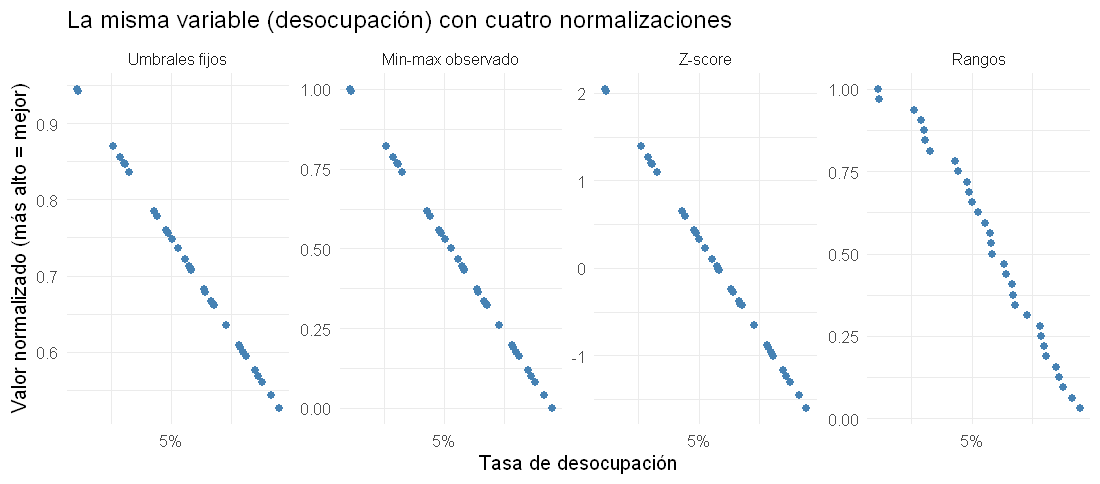

In [14]:
options(repr.plot.height = 4.4)
map(metodos_norm, \(m) tibble(aglomerado = ind$aglomerado,
                              desocupacion = ind$desocupacion,
                              normalizada = normalizadas[[m]][, "desocupacion"],
                              metodo = m)) |>
  list_rbind() |>
  mutate(metodo = factor(metodo, levels = metodos_norm,
                         labels = c("Umbrales fijos", "Min-max observado", "Z-score", "Rangos"))) |>
  ggplot(aes(desocupacion, normalizada)) +
  geom_point(color = "steelblue", size = 2) +
  facet_wrap(~ metodo, scales = "free_y", nrow = 1) +
  scale_x_continuous(labels = scales::label_percent(accuracy = 1), n.breaks = 4) +
  labs(title = "La misma variable (desocupación) con cuatro normalizaciones",
       x = "Tasa de desocupación", y = "Valor normalizado (más alto = mejor)")

> 💡 **Lectura.** Las cuatro normalizaciones respetan el orden (en todos los paneles, más desocupación da un valor más bajo), pero cambian las **distancias**. Con umbrales fijos, la desocupación queda entre 0,53 y 0,94: nadie llega a 0 porque ningún aglomerado se acerca al 20%. Con min-max observado, Viedma queda en 1 y Gran Resistencia en 0, aunque la diferencia real sea de 8 puntos. El z-score va de −1,6 a 2,0, centrado en el promedio. Con rangos los puntos quedan igual de espaciados: la distancia entre el primero y el segundo vale lo mismo que entre el 15 y el 16, aunque en tasa de desocupación sean diferencias muy distintas.

## 6.4 La normalización cambia cuánto pesa cada variable

Una consecuencia menos obvia: la normalización cambia el **rango** en el que se mueve cada variable, y la variable que más se mueve es la que más influye en el índice, aunque todas tengan el mismo peso. Comparemos el rango (máximo menos mínimo) de cada variable normalizada con umbrales fijos y con min-max observado:

In [15]:
tibble(variable = variables,
       rango_fijos     = apply(normalizadas$fijos, 2, \(x) max(x) - min(x)),
       rango_observado = apply(normalizadas$observado, 2, \(x) max(x) - min(x))) |>
  mutate(across(where(is.numeric), \(x) round(x, 2)))

variable,rango_fijos,rango_observado
<chr>,<dbl>,<dbl>
desocupacion,0.42,1
empleo,0.45,1
log_ingreso,0.49,1
sin_descuento,0.59,1
sin_obra_soc,0.52,1
temporario,0.78,1
subocupacion,0.72,1
sobreocup,0.49,1


> 💡 **Lectura.** Con min-max observado todas las variables van de 0 a 1: se estiran hasta ocupar todo el rango, así que todas "mueven" lo mismo el índice, por más chicas que sean sus diferencias reales. Con umbrales fijos, en cambio, la desocupación ocupa 0,42 de la escala y el empleo temporario 0,78. Con los mismos pesos, **el temporario mueve el índice casi el doble que la desocupación**. Ninguna opción es neutral. El min-max observado agranda diferencias chicas (pasar del 1% al 9% de desocupación se vuelve pasar de 1 a 0). Los umbrales fijos respetan la distancia de cada aglomerado a un estándar externo, pero hacen que pesen más las variables con más dispersión.

## 6.5 Normalización y agregación van juntas

Algunas formas de agregar (Parte 8) multiplican las variables, y eso exige que todas sean **estrictamente positivas**. El z-score tiene valores negativos por construcción. El min-max observado le pone **exactamente 0** al peor aglomerado de cada variable. Contemos cuántos ceros y negativos deja cada método:

In [16]:
map(normalizadas, \(m) c(ceros = sum(m == 0), negativos = sum(m < 0))) |> bind_rows(.id = "metodo")

metodo,ceros,negativos
<chr>,<int>,<int>
fijos,0,0
observado,8,0
zscore,0,128
rangos,0,0


> 💡 **Lectura.** El min-max observado deja 8 ceros (el peor aglomerado en cada una de las 8 variables) y el z-score, 128 valores negativos (la mitad de las 256 celdas, por construcción). Umbrales fijos y rangos no dejan ninguno. Esto va a importar en la Parte 8.

# Parte 7. Ponderar: cuánto pesa cada dimensión

## 7.1 Los pesos son tasas de sustitución

La forma intuitiva de pensar los pesos es como "importancia": si la desocupación pesa el doble que la estabilidad, es porque importa el doble. Esa lectura es **engañosa** (Decancq y Lugo, 2013). En un índice aditivo

$$I_a = \sum_j w_j \, I_{aj}$$

el peso $w_j$ dice cuánto sube el índice cuando la variable normalizada $j$ sube un punto. Por eso el cociente entre dos pesos es una **tasa de sustitución**: cuánto de una variable hay que "resignar" para compensar una mejora en otra y dejar el índice igual. Y como cada variable está normalizada con su propio rango, la tasa de sustitución en las **unidades originales** depende del peso **y** de la normalización:

$$\frac{\Delta x_k}{\Delta x_j}\bigg|_{I \text{ constante}} = -\frac{w_j / (x_j^{\text{bueno}} - x_j^{\text{malo}})}{w_k / (x_k^{\text{bueno}} - x_k^{\text{malo}})}$$

Lo vamos a calcular con números concretos en un momento.

## 7.2 Cuatro esquemas de pesos

Organizamos las ocho variables en sus cinco dimensiones. Los pesos los definimos para cada variable, con cuatro esquemas:

1. **Iguales por dimensión** (el esquema base): cada dimensión pesa 1/5 y, dentro de cada una, el peso se reparte en partes iguales entre sus variables. Es lo que hace el IDH.
2. **Iguales por variable**: cada una de las ocho variables pesa 1/8. Parece igual de "neutral", pero las dimensiones con dos variables (acceso, protección, tiempo) terminan pesando el doble que las que tienen una (ingresos, estabilidad). **La cantidad de variables por dimensión es un peso implícito.**
3. **Normativos**: pesos justificados con un argumento explícito. Por ejemplo: el acceso al empleo es condición previa de todo lo demás (0,30); ingresos y protección son el núcleo del trabajo decente (0,25 cada una); estabilidad y tiempo de trabajo son complementarias (0,10 cada una). Otro equipo podría argumentar otros, y eso está bien **siempre que el argumento esté escrito**. Así se arman los pesos "de expertos".
4. **Estadísticos (componentes principales)**: se deja que los datos definan los pesos.

In [17]:
dimension <- c(desocupacion = "Acceso", empleo = "Acceso", log_ingreso = "Ingresos",
               sin_descuento = "Protección", sin_obra_soc = "Protección",
               temporario = "Estabilidad", subocupacion = "Tiempo", sobreocup = "Tiempo")
dimensiones <- c("Acceso", "Ingresos", "Protección", "Estabilidad", "Tiempo")
n_por_dim <- table(dimension)[dimension]           # cuántas variables tiene la dimensión de cada variable

peso_dim_normativo <- c(Acceso = 0.30, Ingresos = 0.25, Protección = 0.25, Estabilidad = 0.10, Tiempo = 0.10)

pesos <- list(
  iguales_dim = setNames(as.numeric(1 / 5 / n_por_dim), variables),
  iguales_var = setNames(rep(1 / 8, 8), variables),
  normativos  = setNames(as.numeric(peso_dim_normativo[dimension] / n_por_dim), variables)
)

### Pesos con componentes principales

El análisis de componentes principales (PCA, que vieron en la clase 15) busca la combinación lineal de las variables con **mayor varianza** entre los aglomerados: la primera componente. Sus *cargas* (los coeficientes de esa combinación) dicen cuánto contribuye cada variable. Una práctica habitual (Nardo et al., 2008) es usar las **cargas al cuadrado** como pesos, porque suman 1.

In [18]:
pca <- prcomp(normalizadas$zscore)          # las variables ya están estandarizadas
summary(pca)$importance[, 1:3]

cargas <- pca$rotation[, 1]
pesos$pca <- cargas^2
round(cbind(carga = cargas, peso = pesos$pca), 3)

,PC1,PC2,PC3
Standard deviation,1.721945,1.500777,0.9677854
Proportion of Variance,0.370640,0.281540,0.1170800
Cumulative Proportion,0.370640,0.652180,0.7692500


,carga,peso
desocupacion,0.037,0.001
empleo,-0.148,0.022
log_ingreso,-0.501,0.251
sin_descuento,-0.547,0.299
sin_obra_soc,-0.533,0.285
temporario,-0.253,0.064
subocupacion,-0.166,0.028
sobreocup,-0.224,0.050


> 💡 **Lectura.** La primera componente explica el 37% de la varianza: lejos de resumir todo, deja afuera casi dos tercios de la información, como era de esperar en un índice formativo. Las cargas están dominadas por las dos variables de protección (0,30 y 0,29 de peso) y el ingreso (0,25): juntas suman el 83% del peso. La desocupación recibe **0,001**: PCA la saca del índice en la práctica, porque no correlaciona con las demás. Además, su carga tiene el signo opuesto al resto (+0,037 frente a cargas negativas): "va para el otro lado", pero al elevar al cuadrado recibe peso positivo igual. Que casi todas las cargas sean negativas no importa: el signo de una componente es arbitrario. Lo que importa es que tengan el mismo signo entre sí.

> ⚠️ **Atención.** Los pesos de PCA tienen sentido en un modelo **reflectivo**: si las variables son manifestaciones de lo mismo, la componente que más varianza explica es una buena estimación del concepto. En un modelo **formativo** como el nuestro hacen lo contrario de lo que queremos: **premian la redundancia** (dos variables que dicen lo mismo suman varianza en común y se llevan más peso) y castigan a las variables que aportan información distinta. Además, elevar al cuadrado borra el signo: una variable que carga "al revés" recibe peso positivo igual.

## 7.3 Los cuatro esquemas, lado a lado

In [19]:
tabla_pesos <- bind_cols(variable = variables, dimension = dimension, as_tibble(pesos))
tabla_pesos |> mutate(across(where(is.numeric), \(x) round(x, 3)))

# Peso total de cada dimensión en cada esquema
tabla_pesos |>
  group_by(dimension) |>
  summarise(across(where(is.numeric), sum)) |>
  mutate(across(where(is.numeric), \(x) round(x, 2)))

variable,dimension,iguales_dim,iguales_var,normativos,pca
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
desocupacion,Acceso,0.1,0.125,0.150,0.001
empleo,Acceso,0.1,0.125,0.150,0.022
log_ingreso,Ingresos,0.2,0.125,0.250,0.251
sin_descuento,Protección,0.1,0.125,0.125,0.299
sin_obra_soc,Protección,0.1,0.125,0.125,0.285
temporario,Estabilidad,0.2,0.125,0.100,0.064
subocupacion,Tiempo,0.1,0.125,0.050,0.028
sobreocup,Tiempo,0.1,0.125,0.050,0.050


dimension,iguales_dim,iguales_var,normativos,pca
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Acceso,0.2,0.25,0.30,0.02
Estabilidad,0.2,0.12,0.10,0.06
Ingresos,0.2,0.12,0.25,0.25
Protección,0.2,0.25,0.25,0.58
Tiempo,0.2,0.25,0.10,0.08


## 7.4 Tasas de sustitución en números

Con los pesos iguales por dimensión y los umbrales fijos, ¿cuántos puntos porcentuales de informalidad compensan **un punto** de desocupación? Desocupación tiene peso $0{,}1$ y rango $0{,}20$; sin descuento jubilatorio, peso $0{,}1$ y rango $0{,}60$:

In [20]:
tasa_sustitucion <- function(j, k, w, norm = umbrales) {
  rango <- \(v) abs(norm$bueno[norm$variable == v] - norm$malo[norm$variable == v])
  (w[[j]] / rango(j)) / (w[[k]] / rango(k))
}

tibble(esquema = names(pesos)[1:3],
       `pp de informalidad por 1 pp de desocupación` =
         map_dbl(pesos[1:3], \(w) tasa_sustitucion("desocupacion", "sin_descuento", w))) |>
  mutate(across(where(is.numeric), \(x) round(x, 2)))

esquema,pp de informalidad por 1 pp de desocupación
<chr>,<dbl>
iguales_dim,3.0
iguales_var,3.0
normativos,3.6


> 💡 **Lectura.** Con pesos iguales por dimensión, **un punto porcentual de desocupación equivale a tres puntos de informalidad**. Un aglomerado que baja su desocupación del 8% al 7% y a la vez sube su informalidad del 35% al 38% queda con exactamente el mismo índice. Con pesos iguales por variable la tasa es la misma (3), porque las dos variables pesan 1/8. Con los normativos sube a 3,6, porque el acceso pesa más. ¿Es razonable cambiar un punto de desocupación por tres de informalidad? Es una pregunta normativa, sin respuesta técnica. Pero sin hacer esta cuenta nadie la hubiera visto. Fijate también que la tasa depende de los **umbrales**: si el umbral "malo" de desocupación fuera 10% en lugar de 20%, se duplicaría.

# Parte 8. Agregar: cómo se combinan las dimensiones

Agregamos en dos etapas, como el IDH. **Primero**, dentro de cada dimensión, promediamos sus variables normalizadas (con los pesos relativos de cada variable dentro de su dimensión). Eso da un **subíndice** por dimensión. **Después**, combinamos los cinco subíndices con el peso de cada dimensión. Las formas de hacer esta segunda etapa son las que vemos ahora.

## 8.1 Aditiva y geométrica: la compensabilidad

**Agregación aritmética** (aditiva):
$$I_a^{A} = \sum_d w_d \, D_{ad} \qquad \frac{\partial I^{A}}{\partial D_d} = w_d$$

**Agregación geométrica** (multiplicativa):
$$I_a^{G} = \prod_d D_{ad}^{\,w_d} \qquad \frac{\partial I^{G}}{\partial D_d} = w_d \, \frac{I^{G}}{D_d}$$

La derivada es lo que importa. En la aditiva, mejorar una dimensión suma siempre lo mismo ($w_d$), no importa desde dónde se parta: un punto en una dimensión **compensa exactamente** un punto (ponderado) en otra. En la geométrica, el aporte de mejorar una dimensión es **más grande cuanto más baja está** ($D_d$ en el denominador): el desbalance se castiga, y una dimensión muy mala no se compensa fácilmente con otras buenas. Si una dimensión vale 0, el índice vale 0, sin importar el resto.

Un ejemplo de pizarrón con tres dimensiones de igual peso:

In [21]:
tibble(aglomerado = c("A (desbalanceado)", "B (parejo)"),
       acceso = c(0.9, 0.7), ingresos = c(0.9, 0.7), proteccion = c(0.3, 0.7)) |>
  mutate(aritmetica = (acceso + ingresos + proteccion) / 3,
         geometrica = (acceso * ingresos * proteccion)^(1/3)) |>
  mutate(across(where(is.numeric), \(x) round(x, 3)))

aglomerado,acceso,ingresos,proteccion,aritmetica,geometrica
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A (desbalanceado),0.9,0.9,0.3,0.7,0.624
B (parejo),0.7,0.7,0.7,0.7,0.700


> 💡 **Lectura.** Con la suma, A y B empatan (0,7): el 0,3 de protección de A queda compensado por sus 0,9. Con el producto, B queda arriba, porque la geométrica castiga el desbalance de A. Elegir entre las dos es decidir **cuánto se acepta que una dimensión compense a otra**: ¿un aglomerado con mucho empleo pero casi todo informal funciona igual de bien que uno con valores intermedios en todo? Es una decisión normativa. El PNUD pasó de la aritmética a la geométrica en 2010 justamente por esto.

## 8.2 Agregaciones no compensatorias: Borda y conteo

Las dos anteriores usan las **magnitudes** de los subíndices. Hay alternativas que usan solo el **orden** o un **umbral**, y por eso limitan mucho más la compensación:

- **Borda**: en cada dimensión se ordena a los aglomerados (1 al peor, 32 al mejor) y el índice es la suma ponderada de las posiciones. Lo único que importa es **a cuántos supera** el aglomerado en cada dimensión, no por cuánto. Ser apenas mejor que el resto vale lo mismo que ser mucho mejor.
- **Conteo de privaciones** (estilo Alkire-Foster, el método del índice de pobreza multidimensional): en cada dimensión se marca al aglomerado como **privado** si está en el tercio inferior. El índice es $1$ menos la suma ponderada de privaciones. Un aglomerado que no está en el tercio inferior en nada tiene índice 1, sin importar cuán alto esté.

La función `calcular_indice()` hace las dos etapas. Recibe la matriz normalizada, los pesos de las variables y el método de agregación, y devuelve un valor por aglomerado.

In [22]:
subindices <- function(m, w) {
  sapply(dimensiones, \(d) {
    v <- names(dimension)[dimension == d]
    as.numeric(m[, v, drop = FALSE] %*% (w[v] / sum(w[v])))
  })
}

calcular_indice <- function(m, w, agregacion) {
  D   <- subindices(m, w)
  w_d <- tapply(w, dimension[names(w)], sum)[dimensiones]   # peso de cada dimensión
  switch(agregacion,
    aritmetica = as.numeric(D %*% w_d),
    geometrica = {
      if (any(D <= 0)) return(rep(NA_real_, nrow(D)))      # no está definida con ceros o negativos
      as.numeric(exp(log(D) %*% w_d))
    },
    borda      = as.numeric(apply(D, 2, rank) %*% w_d),
    conteo     = as.numeric(1 - (apply(D, 2, \(x) x <= quantile(x, 1/3)) %*% w_d)))
}

posicion <- function(indice) rank(-indice, ties.method = "min")   # 1 = el mejor

Calculamos las cuatro agregaciones con la normalización y los pesos base, y vemos qué aglomerados cambian más de posición:

In [23]:
agregaciones <- c("aritmetica", "geometrica", "borda", "conteo")

comparacion_agreg <- map(set_names(agregaciones), \(a)
  posicion(calcular_indice(normalizadas$fijos, pesos$iguales_dim, a))) |>
  as_tibble() |>
  mutate(aglomerado = ind$aglomerado, .before = 1)

comparacion_agreg |>
  mutate(salto_max = pmax(aritmetica, geometrica, borda, conteo) -
                     pmin(aritmetica, geometrica, borda, conteo)) |>
  arrange(desc(salto_max)) |>
  head(8)

aglomerado,aritmetica,geometrica,borda,conteo,salto_max
<chr>,<int>,<int>,<int>,<int>,<int>
Partidos GBA,23,22,23,5,18
La Rioja,29,30,20,16,14
San Nicolás - Villa Const.,17,15,19,5,14
Salta,27,25,28,16,12
Gran Tucumán - T. Viejo,26,28,27,16,12
Mar del Plata - Batán,16,14,16,5,11
Gran La Plata,20,21,24,16,8
Gran Rosario,9,9,9,1,8


> 💡 **Lectura.** Entre la aritmética y la geométrica los saltos son chicos (de dos o tres posiciones), salvo en perfiles muy desbalanceados. Santiago del Estero, por ejemplo, está 12º con la aritmética y 19º con la geométrica: su protección es muy baja (0,25) y la geométrica no deja que su excelente estabilidad la compense (no aparece en la tabla porque su salto máximo es 7). Borda mueve a La Rioja del 29 al 20. La Rioja tiene la peor estabilidad de todos (0,20), muy lejos del resto: con la aritmética esa distancia le cuesta mucho, y con Borda solo le cuesta "un último puesto", sin importar por cuánto. El conteo produce los saltos más grandes, pero por una razón distinta: tiene **muy poca resolución**. Partidos GBA pasa del 23 al 5 porque está en el tercio inferior en una sola dimensión (acceso). Con el conteo, 11 aglomerados empatan en el puesto 5 y 10 en el 16.

In [24]:
# Correlación de Spearman entre las posiciones que da cada agregación
round(cor(select(comparacion_agreg, -aglomerado), method = "spearman"), 3)

,aritmetica,geometrica,borda,conteo
aritmetica,1.000,0.977,0.964,0.853
geometrica,0.977,1.000,0.958,0.865
borda,0.964,0.958,1.000,0.842
conteo,0.853,0.865,0.842,1.000


> 💡 **Lectura.** Aritmética, geométrica y Borda dan órdenes muy parecidos (correlaciones entre 0,96 y 0,98): con estos datos, el grado de compensación cambia poco el ranking general y mucho el de unos pocos aglomerados desbalanceados. El conteo es el que más se aleja (entre 0,84 y 0,87). Es otra forma de mirar: en lugar de "qué tan bien está", pregunta "en cuántas cosas está mal".

## 8.3 Lo que no se puede: geométrica con z-score o con min-max observado

In [25]:
calcular_indice(normalizadas$zscore, pesos$iguales_dim, "geometrica")[1:5]
calcular_indice(normalizadas$observado, pesos$iguales_dim, "geometrica")[1:5]

[1] NA NA NA NA NA

[1] NA NA NA NA NA

> 💡 **Lectura.** La geométrica devuelve `NA` con las dos normalizaciones: el z-score tiene valores negativos y el min-max observado deja subíndices en 0. La salida habitual es sumar una constante o poner un piso (por ejemplo, 0,01), pero ese piso **también es una decisión** y puede mover mucho el resultado de los aglomerados que lo tocan. Con umbrales fijos el problema no aparece, porque elegimos los umbrales para que nadie quede en el borde. **La normalización y la agregación se eligen juntas.**

# Parte 9. El índice base y cómo se lee

## 9.1 El ranking

Juntamos las decisiones que tomamos como "base": umbrales fijos, ingreso en logaritmo y ajustado por región, pesos iguales por dimensión y agregación aritmética.

In [26]:
D_base <- subindices(normalizadas$fijos, pesos$iguales_dim)
indice_base <- calcular_indice(normalizadas$fijos, pesos$iguales_dim, "aritmetica")

base <- tibble(aglomerado = ind$aglomerado, indice = indice_base) |>
  bind_cols(as_tibble(D_base)) |>
  mutate(posicion = posicion(indice)) |>
  arrange(posicion)

base |> mutate(across(where(is.double), \(x) round(x, 3)))

aglomerado,indice,Acceso,Ingresos,Protección,Estabilidad,Tiempo,posicion
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Ciudad de Bs. As.,0.704,0.761,0.792,0.596,0.772,0.598,1
Viedma - Carmen de Pat.,0.672,0.621,0.567,0.606,0.887,0.679,2
Cdro. Rivadavia - R. Tilly,0.658,0.580,0.550,0.674,0.943,0.543,3
Neuquén - Plottier,0.629,0.665,0.646,0.709,0.590,0.537,4
Ushuaia - Río Grande,0.626,0.576,0.625,0.740,0.604,0.587,5
Río Gallegos,0.617,0.496,0.550,0.687,0.833,0.521,6
Gran Santa Fé,0.589,0.556,0.510,0.514,0.822,0.542,7
Bahía Blanca - Cerri,0.583,0.532,0.586,0.564,0.753,0.481,8
Gran Rosario,0.549,0.614,0.556,0.428,0.650,0.495,9


> 💡 **Lectura.** Arriba de todo está la Ciudad de Buenos Aires (0,70), con el mejor ingreso y el mejor acceso. Le siguen cinco aglomerados patagónicos (Viedma, Comodoro Rivadavia, Neuquén, Ushuaia y Río Gallegos), con mucha protección y estabilidad. Al fondo están Concordia (0,36), Gran San Juan, Corrientes, La Rioja y Gran Córdoba. Un caso interesante es Santiago del Estero, 12º a pesar de tener el 45% de los asalariados sin descuento jubilatorio. Su desocupación muy baja (1,2%) y casi nada de empleo temporario compensan su protección (0,25). Es la **compensación** de la agregación aditiva en acción.

## 9.2 Descomposición: qué hay detrás de cada número

Un índice compuesto publicado solo como número **esconde** sus razones. Dos aglomerados con el mismo valor pueden llegar ahí por caminos muy distintos. Por eso es buena práctica mostrar la **descomposición**: cuánto aporta cada dimensión al total. En el índice aditivo es directo: el aporte de la dimensión $d$ es $w_d \cdot D_{ad}$.

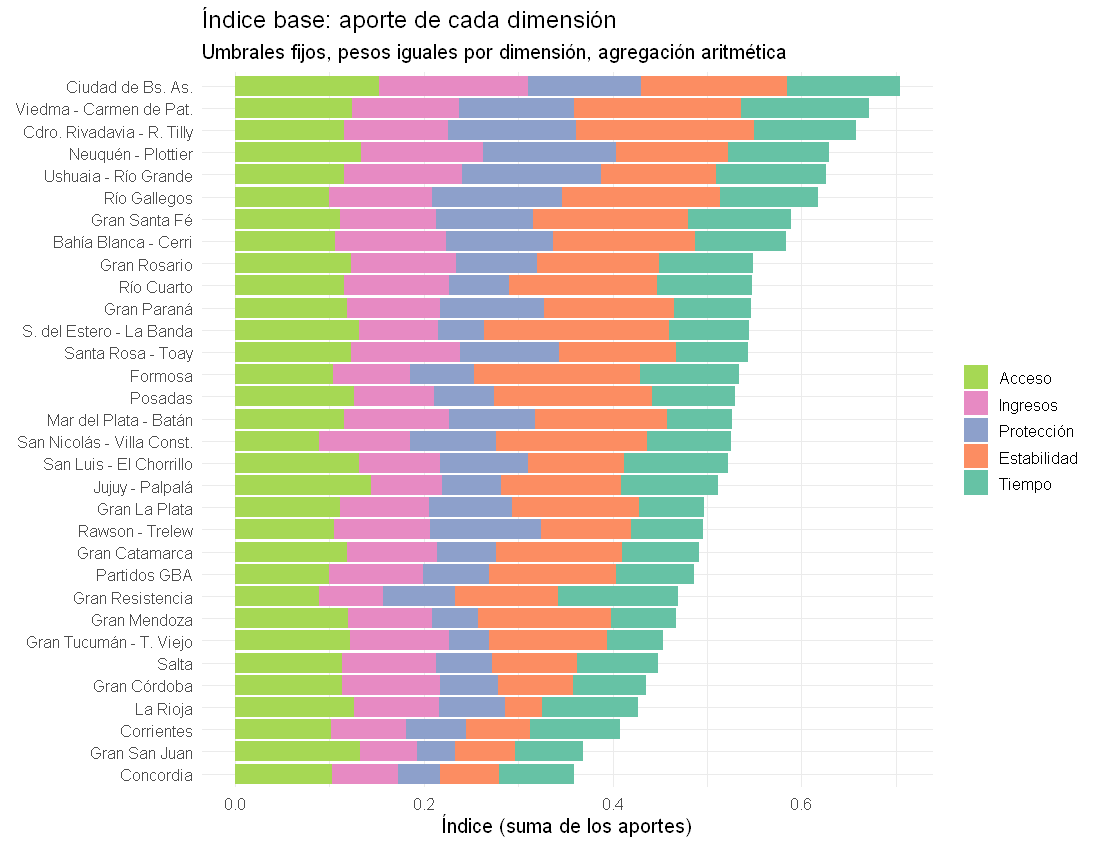

In [27]:
options(repr.plot.height = 7.7)
base |>
  pivot_longer(all_of(dimensiones), names_to = "dimension", values_to = "valor") |>
  mutate(aporte = valor / 5,
         dimension = factor(dimension, levels = rev(dimensiones))) |>
  ggplot(aes(aporte, reorder(aglomerado, indice), fill = dimension)) +
  geom_col() +
  scale_fill_brewer(palette = "Set2", guide = guide_legend(reverse = TRUE)) +
  labs(title = "Índice base: aporte de cada dimensión",
       subtitle = "Umbrales fijos, pesos iguales por dimensión, agregación aritmética",
       x = "Índice (suma de los aportes)", y = NULL, fill = NULL)

> 💡 **Lectura.** Lo que separa a los de arriba de los de abajo no es el acceso (las barras verdes son parecidas en casi todos), sino la estabilidad y la protección. El gráfico también muestra que **el mismo número puede esconder perfiles muy distintos**. Santiago del Estero (12º, 0,545) y Santa Rosa (13º, 0,544) tienen prácticamente el mismo índice. Santiago llega por estabilidad (0,98) y acceso; Santa Rosa, por protección (0,52 contra 0,25) e ingresos (0,58 contra 0,42). Son dos mercados de trabajo muy distintos, que requerirían políticas distintas, y el índice solo no lo dice. Por eso un índice interpretable **publica la descomposición**, no solo el número.

## 9.3 Pesos nominales y pesos efectivos

Con pesos iguales, ¿cada dimensión influye lo mismo en el resultado? No necesariamente. La dimensión que **más varía** entre aglomerados y la que **más correlaciona** con las demás termina moviendo más el índice (Paruolo, Saisana y Saltelli, 2013). Una medida simple de la influencia efectiva es la correlación al cuadrado de cada subíndice con el índice ($R^2$), reescalada para que sume 1.

In [28]:
tibble(dimension = dimensiones,
       desvio = apply(D_base, 2, sd),
       r2 = apply(D_base, 2, \(x) cor(x, indice_base)^2)) |>
  mutate(peso_nominal = 0.2, influencia = r2 / sum(r2)) |>
  mutate(across(where(is.numeric), \(x) round(x, 3)))

dimension,desvio,r2,peso_nominal,influencia
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Acceso,0.072,0.069,0.2,0.032
Ingresos,0.099,0.568,0.2,0.261
Protección,0.157,0.645,0.2,0.296
Estabilidad,0.194,0.529,0.2,0.243
Tiempo,0.093,0.365,0.2,0.168


> 💡 **Lectura.** El acceso tiene peso nominal 0,2, pero su influencia efectiva es **0,03**: casi no mueve el índice. Hay dos razones. Es la dimensión que menos varía entre aglomerados (desvío 0,072, frente a 0,194 de estabilidad) y no correlaciona con las demás. Protección (0,30), ingresos (0,26) y estabilidad (0,24) son las que en la práctica ordenan el ranking. Quien lea "pesos iguales" y suponga que la desocupación explica un quinto del resultado se equivoca. Si se quisiera que el acceso pese de verdad un quinto, habría que darle bastante más de un quinto de peso nominal (Becker et al., 2017).

# Parte 10. Análisis de sensibilidad

Hasta acá tomamos decisiones de a una y vimos que cada una mueve algo. El **análisis de sensibilidad** las mueve **todas juntas** y pregunta: dado todo lo que podríamos haber decidido distinto, ¿qué tan seguro es el lugar de cada aglomerado? (Saisana, Saltelli y Tarantola, 2005).

## 10.1 Todas las combinaciones

Tenemos cuatro decisiones con alternativas razonables:

| Decisión | Alternativas |
|:--|:--|
| Normalización | Umbrales fijos, min-max observado, z-score, rangos |
| Pesos | Iguales por dimensión, iguales por variable, normativos, PCA |
| Agregación | Aritmética, geométrica, Borda, conteo |
| Ajuste regional del ingreso | Sí, no |

Son $4 \times 4 \times 4 \times 2 = 128$ combinaciones. Sacamos las 16 que no se pueden calcular (geométrica con z-score o con min-max observado) y quedan 112. Como son pocas, **las calculamos todas**. Cuando las combinaciones son demasiadas, se sortea una muestra al azar: eso es un *Monte Carlo* (lo hacemos en la sección 10.3 con los pesos).

In [29]:
especificaciones <- expand_grid(normalizacion = metodos_norm,
                                ponderacion = names(pesos),
                                agregacion = agregaciones,
                                ajuste_regional = c(TRUE, FALSE)) |>
  filter(!(agregacion == "geometrica" & normalizacion %in% c("observado", "zscore"))) |>
  mutate(id = row_number(), .before = 1)

# Las matrices normalizadas sin ajuste regional
normalizadas_sin_ajuste <- map(set_names(metodos_norm), \(m) normalizar_todo(ind, m, ajuste_regional = FALSE))

resultados <- especificaciones |>
  mutate(indice = pmap(list(normalizacion, ponderacion, agregacion, ajuste_regional), \(n, p, a, r) {
    m <- if (r) normalizadas[[n]] else normalizadas_sin_ajuste[[n]]
    calcular_indice(m, pesos[[p]], a)
  })) |>
  mutate(aglomerado = list(ind$aglomerado)) |>
  unnest(c(indice, aglomerado)) |>
  group_by(id) |>
  mutate(posicion = posicion(indice)) |>
  ungroup()

nrow(especificaciones)

[1] 112

Para cada aglomerado resumimos las 112 posiciones con la mediana y el rango entre el percentil 5 y el 95:

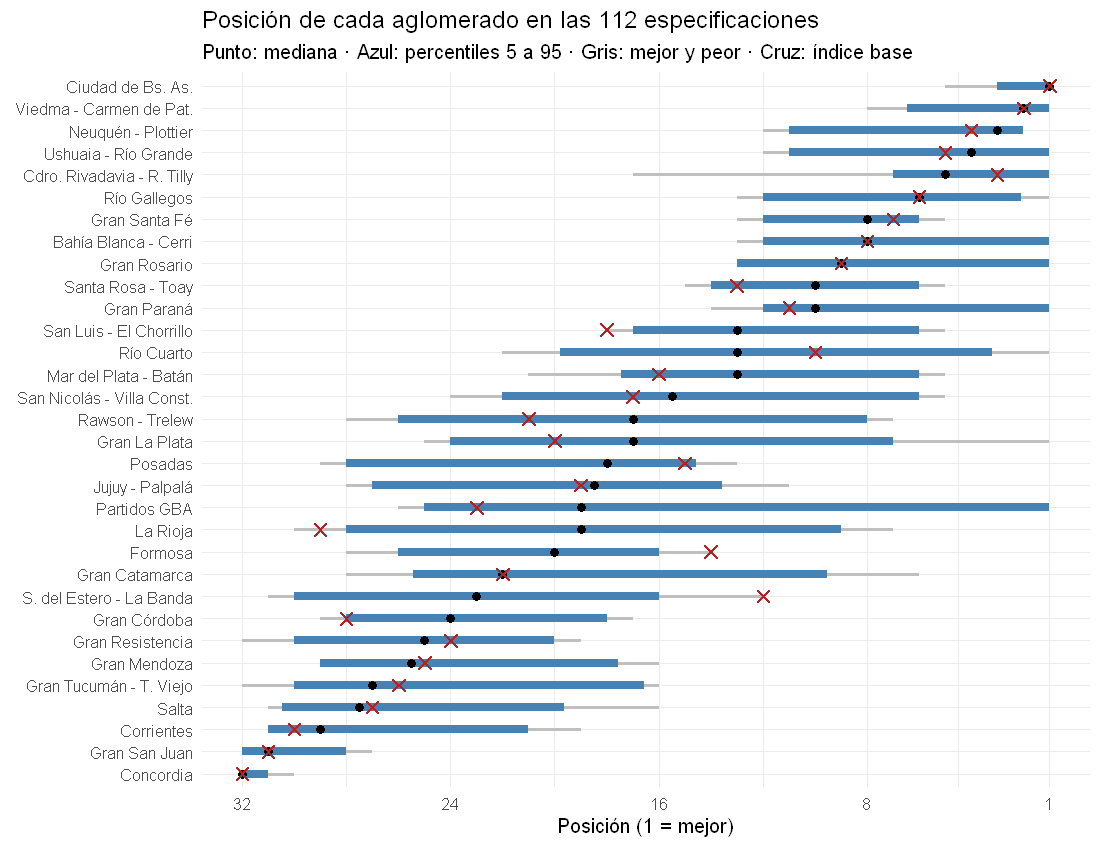

In [30]:
options(repr.plot.height = 7.7)
bandas <- resultados |>
  group_by(aglomerado) |>
  summarise(p05 = quantile(posicion, 0.05), mediana = median(posicion),
            p95 = quantile(posicion, 0.95), mejor = min(posicion), peor = max(posicion)) |>
  left_join(select(base, aglomerado, posicion_base = posicion), by = "aglomerado")

ggplot(bandas, aes(y = reorder(aglomerado, -mediana))) +
  geom_linerange(aes(xmin = mejor, xmax = peor), color = "grey75", linewidth = 1) +
  geom_linerange(aes(xmin = p05, xmax = p95), color = "steelblue", linewidth = 2.5) +
  geom_point(aes(x = mediana), size = 2.5) +
  geom_point(aes(x = posicion_base), shape = 4, color = "firebrick", size = 3, stroke = 1.3) +
  scale_x_reverse(breaks = c(1, 8, 16, 24, 32)) +
  labs(title = "Posición de cada aglomerado en las 112 especificaciones",
       subtitle = "Punto: mediana · Azul: percentiles 5 a 95 · Gris: mejor y peor · Cruz: índice base",
       x = "Posición (1 = mejor)", y = NULL)

> 💡 **Lectura.** Los extremos son robustos. La Ciudad de Buenos Aires está entre el 1º y el 5º puesto en las 112 versiones, Viedma entre el 1º y el 8º, y Concordia entre el 30º y el 32º. En el medio, la incertidumbre es enorme: Partidos GBA puede estar en cualquier lugar entre el 1º y el 26º, Gran La Plata entre el 1º y el 25º, y La Rioja entre el 7º y el 30º. Para esos aglomerados, decir "está en el puesto 20" sin aclarar las decisiones es engañoso. A veces la cruz roja (el índice base) queda lejos de la mediana. Santiago del Estero está 12º en la base, pero su mediana es 23: la versión base es de las más favorables para él.

## 10.2 ¿Qué decisión pesa más?

Las bandas dicen **cuánto** se mueve cada aglomerado, pero no **por qué**. Para saber qué decisión hay que justificar con más cuidado, medimos qué parte de la variación de las posiciones explica cada decisión por sí sola. Para un aglomerado y una decisión (por ejemplo, la agregación):

1. Se calcula la posición promedio con cada alternativa de esa decisión (promediando todo lo demás).
2. Si esos promedios son muy distintos entre sí, la decisión importa mucho; si son parecidos, importa poco.
3. La varianza de esos promedios dividida por la varianza total de las posiciones es la **parte explicada** por la decisión.

$$S_{\text{decisión}} = \frac{\operatorname{Var}\big(\,\mathbb{E}[\text{posición} \mid \text{decisión}]\,\big)}{\operatorname{Var}(\text{posición})}$$

Es la misma idea que el $R^2$ de una regresión de la posición contra la decisión, y una versión simple de los **índices de Sobol de primer orden** que usa el JRC. Lo que no suma 1 es la parte que se explica por **interacciones** entre decisiones (por ejemplo, que la normalización importe con la aritmética y no con Borda).

In [31]:
parte_explicada <- function(datos, decision) {
  datos |>
    group_by(aglomerado) |>
    mutate(var_total = mean((posicion - mean(posicion))^2)) |>
    group_by(aglomerado, var_total, alternativa = .data[[decision]]) |>
    summarise(media = mean(posicion), n = n(), .groups = "drop_last") |>
    summarise(var_explicada = sum(n * (media - weighted.mean(media, n))^2) / sum(n), .groups = "drop") |>
    summarise(parte = sum(var_explicada) / sum(var_total)) |>
    pull(parte)
}

decisiones <- c("normalizacion", "ponderacion", "agregacion", "ajuste_regional")
partes <- tibble(decision = decisiones,
                 parte_explicada = map_dbl(decisiones, \(d) parte_explicada(resultados, d)))
partes |>
  add_row(decision = "interacciones (resto)", parte_explicada = 1 - sum(partes$parte_explicada)) |>
  mutate(parte_explicada = round(parte_explicada, 3))

decision,parte_explicada
<chr>,<dbl>
normalizacion,0.044
ponderacion,0.322
agregacion,0.387
ajuste_regional,0.028
interacciones (resto),0.219


> 💡 **Lectura.** La agregación explica el 39% de la variación de las posiciones y los pesos el 32%. La normalización explica solo el 4% y el ajuste regional, el 3%. El 22% restante son interacciones. En este caso, entonces, la discusión que hay que dar en serio es **cuánto pesa cada dimensión y cuánto se compensan entre sí**. Elegir entre las normalizaciones razonables importa poco. Ojo con la lectura: buena parte del efecto de la agregación viene del conteo, que con sus empates mueve mucho las posiciones. El resultado depende de qué alternativas se pusieron sobre la mesa, y eso también es una decisión.

## 10.3 Monte Carlo sobre los pesos

Los cuatro esquemas de pesos son solo cuatro puntos de un universo infinito. Para ver la incertidumbre de los pesos en general, sorteamos 2.000 juegos de pesos al azar para las cinco dimensiones. Usamos una **distribución de Dirichlet** con todos sus parámetros iguales a 1, que reparte el total entre las cinco dimensiones de forma que cualquier combinación de pesos que sume 1 es igual de probable. (El truco para sortearla: cinco números con distribución exponencial, divididos por su suma.) Dejamos fijo todo lo demás en la versión base.

In [32]:
set.seed(2026)
n_sim <- 2000
sim_pesos <- map(1:n_sim, \(s) {
  w_d <- rexp(5); w_d <- setNames(w_d / sum(w_d), dimensiones)
  w <- setNames(as.numeric(w_d[dimension] / n_por_dim), variables)
  tibble(sim = s, aglomerado = ind$aglomerado,
         posicion = posicion(calcular_indice(normalizadas$fijos, w, "aritmetica")))
}) |> list_rbind()

sim_pesos |>
  group_by(aglomerado) |>
  summarise(p05 = quantile(posicion, 0.05), mediana = median(posicion), p95 = quantile(posicion, 0.95),
            prob_top5 = mean(posicion <= 5), prob_ultimos5 = mean(posicion >= 28)) |>
  arrange(mediana)

aglomerado,p05,mediana,p95,prob_top5,prob_ultimos5
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Ciudad de Bs. As.,1.00,1,5.00,0.9710,0.0000
Viedma - Carmen de Pat.,1.00,2,5.00,0.9625,0.0000
Cdro. Rivadavia - R. Tilly,1.00,3,5.00,0.9590,0.0000
Neuquén - Plottier,2.00,4,13.00,0.6755,0.0000
Ushuaia - Río Grande,1.00,5,13.00,0.6895,0.0000
Río Gallegos,4.00,6,13.00,0.3585,0.0000
Bahía Blanca - Cerri,6.00,8,15.00,0.0105,0.0000
Gran Santa Fé,5.00,8,12.00,0.0735,0.0000
Gran Rosario,8.00,12,16.00,0.0015,0.0000


> 💡 **Lectura.** Con 2.000 juegos de pesos al azar, la Ciudad de Buenos Aires, Viedma y Comodoro Rivadavia quedan entre los cinco primeros en más del 95% de los sorteos. Concordia queda entre los cinco últimos en el 99,8% y Gran San Juan en el 93%. En el medio aparecen los aglomerados cuya posición depende de los pesos. Santiago del Estero va del 3º al 27º entre el percentil 5 y el 95: su lugar depende casi por completo de cuánto pese la protección (donde está muy mal) frente a la estabilidad y el acceso (donde está muy bien). Un aglomerado con un perfil desbalanceado es **sensible a los pesos** por definición.

## 10.4 Sacar una dimensión por vez

Otra pregunta de sensibilidad: ¿qué pasa si una dimensión no estuviera? Si sacarla no cambia nada, aporta poco al índice, por más importante que sea en el marco conceptual. Si cambia mucho, el índice **depende** de ella. Repetimos el índice base sacando cada dimensión (y repartiendo su peso entre las otras).

In [33]:
# Índice base sin la dimensión d: promedio simple de las otras cuatro
sin_dimension <- function(d) rowMeans(D_base[, setdiff(dimensiones, d)])

posicion_base <- posicion(indice_base)

loo <- map(dimensiones, \(d) {
  pos <- posicion(sin_dimension(d))
  tibble(se_saca = d,
         cambio_medio = mean(abs(pos - posicion_base)),
         cambio_max = max(abs(pos - posicion_base)),
         spearman_con_base = cor(pos, posicion_base, method = "spearman"))
}) |> list_rbind()

loo |> mutate(across(where(is.double), \(x) round(x, 2)))

se_saca,cambio_medio,cambio_max,spearman_con_base
<chr>,<dbl>,<int>,<dbl>
Acceso,1.50,8,0.97
Ingresos,1.69,6,0.97
Protección,2.19,8,0.95
Estabilidad,3.31,15,0.86
Tiempo,1.44,4,0.98


> 💡 **Lectura.** Sacar la estabilidad es lo que más mueve el ranking: 3,3 posiciones en promedio, hasta 15 para algún aglomerado, y la correlación con el ranking base baja a 0,86. Sacar el tiempo de trabajo o el acceso cambia poco (1,4 y 1,5 posiciones en promedio). Es coherente con los pesos efectivos: la estabilidad es la dimensión que más varía. Que sacar el acceso cambie poco **no quiere decir que no importe** conceptualmente. Quiere decir que, con estos datos, no discrimina entre aglomerados.

# Parte 11. Validación: ¿cómo sabemos si el índice está "bien"?

## 11.1 Dos usos del mismo índice

Llegamos a 112 versiones del índice que dan rankings parecidos pero no iguales. La pregunta natural es **cuál es la correcta**. La respuesta depende de para qué se construyó el índice.

**Uso 1: describir.** Si el objetivo es ordenar a los aglomerados según "qué tan bien funciona su mercado de trabajo", el índice **es** la definición operativa del concepto. No existe un "verdadero funcionamiento del mercado de trabajo" medido por otro lado contra el cual comparar. Lo único que se puede hacer es lo que ya hicimos: explicitar las decisiones, mostrar que el resultado es razonablemente robusto (o dónde no lo es) y hacer que el número sea **interpretable** (descomposición). Cualquier versión que esté bien justificada es tan válida como las otras. La elección entre ellas es una discusión **conceptual y normativa**, no estadística.

**Uso 2: testear una hipótesis.** Si el índice se construye como insumo para responder una pregunta planteada **de antemano**, entonces sí aparece un criterio externo: la hipótesis dice qué relación debería tener el índice con **otra variable que no está en el índice**. El índice se puede evaluar según si captura esa relación. Es la **validación externa**.

## 11.2 La hipótesis

Planteamos la hipótesis **antes** de mirar los datos:

> **Hipótesis.** En los aglomerados donde el mercado de trabajo funciona peor, una proporción mayor de hogares depende de transferencias en dinero (AUH, otros planes sociales o ayuda de iglesias y ONG).

El mecanismo es directo: si el trabajo no alcanza para sostener al hogar (porque no se consigue, porque paga poco o porque no tiene protección), el hogar recurre a otras fuentes. Si el índice captura el funcionamiento del mercado de trabajo, debería tener una **correlación negativa** con el porcentaje de hogares que reciben transferencias. La variable sale de la base de **hogares** (`V5_01`, `V5_02` y `V5_03`), y **no forma parte del índice**.

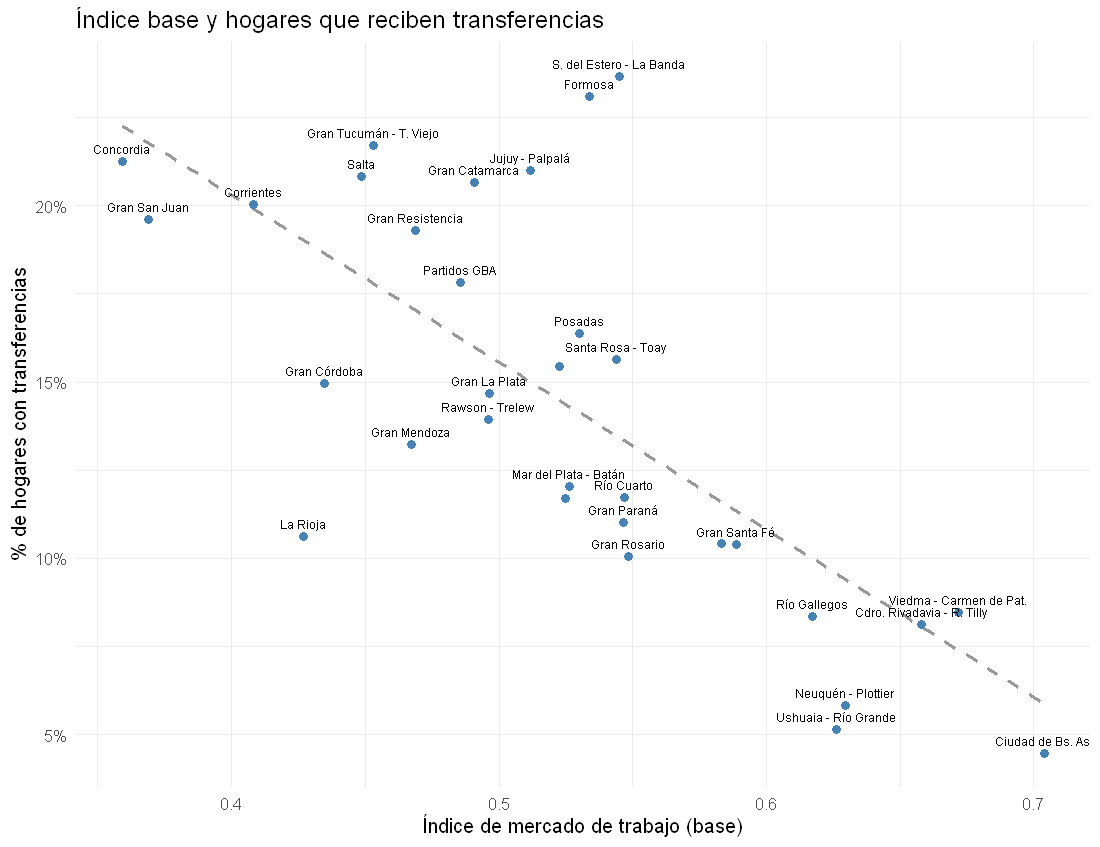

In [34]:
validacion <- hogares |>
  group_by(AGLOMERADO) |>
  summarise(transferencias = sum(PONDERA * (V5_01 == 1 | V5_02 == 1 | V5_03 == 1)) / sum(PONDERA)) |>
  left_join(nombres, by = "AGLOMERADO")

base |>
  left_join(validacion, by = "aglomerado") |>
  ggplot(aes(indice, transferencias)) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, color = "grey60", linetype = "dashed") +
  geom_point(color = "steelblue", size = 2.5) +
  geom_text(aes(label = aglomerado), size = 2.8, vjust = -0.8, check_overlap = TRUE) +
  scale_y_continuous(labels = scales::percent) +
  labs(title = "Índice base y hogares que reciben transferencias",
       x = "Índice de mercado de trabajo (base)", y = "% de hogares con transferencias")

## 11.3 La hipótesis en las 112 especificaciones

Calculamos la correlación de Spearman (de rangos) entre el índice y el porcentaje de hogares con transferencias, para cada una de las 112 versiones. Con 32 aglomerados, una correlación por debajo de $-0{,}35$ es significativa al 5% (la hipótesis nula es que no hay relación).

ponderacion,rho_min,rho_mediana,rho_max,sostienen_hipotesis
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
iguales_dim,-0.83,-0.77,-0.70,1
iguales_var,-0.83,-0.77,-0.71,1
normativos,-0.86,-0.79,-0.72,1
pca,-0.88,-0.86,-0.71,1


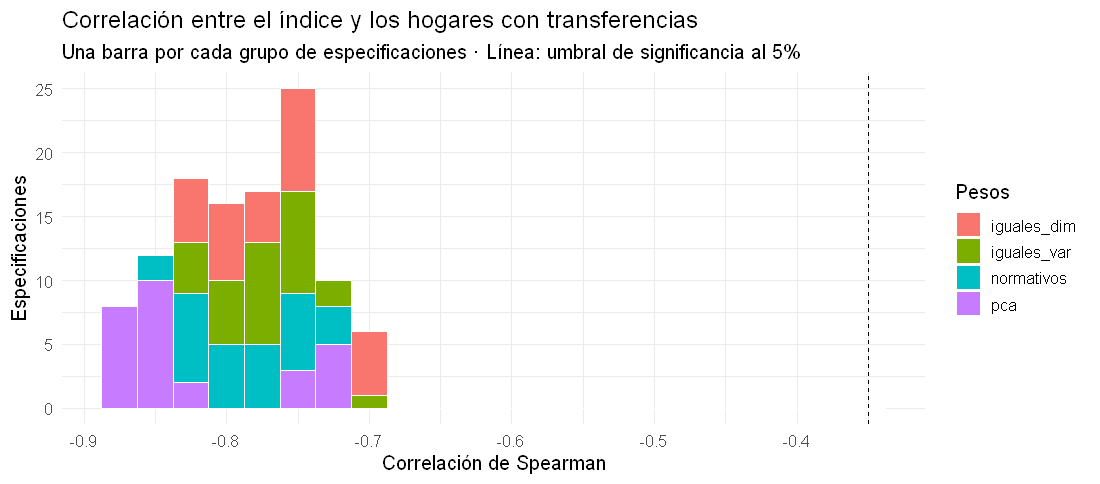

In [35]:
options(repr.plot.height = 4.4)
corr_validacion <- resultados |>
  left_join(validacion, by = "aglomerado") |>
  group_by(id, normalizacion, ponderacion, agregacion, ajuste_regional) |>
  summarise(rho = cor(indice, transferencias, method = "spearman"), .groups = "drop")

ggplot(corr_validacion, aes(rho, fill = ponderacion)) +
  geom_histogram(binwidth = 0.025, color = "white") +
  geom_vline(xintercept = -0.35, linetype = "dashed") +
  labs(title = "Correlación entre el índice y los hogares con transferencias",
       subtitle = "Una barra por cada grupo de especificaciones · Línea: umbral de significancia al 5%",
       x = "Correlación de Spearman", y = "Especificaciones", fill = "Pesos")

corr_validacion |>
  group_by(ponderacion) |>
  summarise(rho_min = min(rho), rho_mediana = median(rho), rho_max = max(rho),
            sostienen_hipotesis = mean(rho < -0.35)) |>
  mutate(across(where(is.numeric), \(x) round(x, 2)))

> 💡 **Lectura.** El gráfico de la sección 11.2 muestra la relación esperada: a mayor índice, menos hogares con transferencias. Y la hipótesis se sostiene en **las 112 especificaciones**: todas las correlaciones están entre −0,70 y −0,88, por debajo del umbral de −0,35. La validación dice que el índice sirve para esta pregunta, cualquiera sea la versión. **Pero no elige entre versiones.** Si la usáramos para elegir, pasaría algo incómodo: la versión que "mejor valida" es la de rangos con pesos de PCA y Borda (−0,88), y la que "peor valida" es justamente la base (−0,70). PCA valida mejor porque pone el 58% del peso en protección, y la protección es la dimensión más ligada a la variable de validación, como vemos ahora.

## 11.4 ¿La validación es independiente?

Antes de celebrar hay que preguntarse si la variable de validación es **realmente externa** al índice. Acá hay un problema: la AUH, la transferencia más común, la cobran los hijos de trabajadores **informales** o desocupados. La relación con la dimensión de protección (informalidad) es en parte **institucional**: está escrita en la regla del programa. Una prueba simple es repetir la validación con el índice **sin** la dimensión de protección:

In [36]:
tibble(indice = c("Base (5 dimensiones)", "Sin protección"),
       rho = c(cor(indice_base,
                   validacion$transferencias[match(ind$aglomerado, validacion$aglomerado)], method = "spearman"),
               cor(sin_dimension("Protección"),
                   validacion$transferencias[match(ind$aglomerado, validacion$aglomerado)], method = "spearman"))) |>
  mutate(rho = round(rho, 2))

# Correlación de cada dimensión (subíndice) con las transferencias
transferencias <- validacion$transferencias[match(ind$aglomerado, validacion$aglomerado)]
round(apply(D_base, 2, \(x) cor(x, transferencias, method = "spearman")), 2)

indice,rho
<chr>,<dbl>
Base (5 dimensiones),-0.70
Sin protección,-0.53


Acceso    Ingresos  Protección Estabilidad      Tiempo 
      -0.10       -0.72       -0.80       -0.25       -0.46

> 💡 **Lectura.** Sin la dimensión de protección, la correlación baja de −0,70 a −0,53, pero sigue siendo significativa: la hipótesis sobrevive aun sacando la parte que se pisa institucionalmente con la AUH. La correlación de cada dimensión por separado muestra qué parte del mercado de trabajo sostiene la hipótesis: protección (−0,80) e ingresos (−0,72) mucho, tiempo de trabajo algo (−0,46), estabilidad poco (−0,25) y el acceso casi nada (−0,10). **Donde hay menos desocupación no hay menos hogares con transferencias.** Lo que se relaciona con las transferencias es la calidad del empleo, no la cantidad. Ese hallazgo es más informativo que el número de la validación.

> ⚠️ **Atención: la validación circular.** Un error frecuente es "validar" un índice contra una variable que ya está adentro. Por ejemplo, contra el ingreso per cápita del hogar: como el ingreso horario es una dimensión del índice, una correlación positiva está **garantizada** de antemano y no prueba nada. Lo comprobamos abajo. Una buena validación externa usa una variable que el índice **no contiene** y que el marco conceptual dice que **debería anticipar**.

In [37]:
ipcf <- hogares |>
  filter(PONDIH > 0) |>
  group_by(ANO4, TRIMESTRE) |>
  mutate(ipcf_rel = IPCF / mediana_ponderada(IPCF, PONDIH)) |>
  ungroup() |>
  left_join(factor_regional, by = "REGION") |>
  group_by(AGLOMERADO) |>
  summarise(ipcf = mediana_ponderada(ipcf_rel / factor, PONDIH)) |>
  left_join(nombres, by = "AGLOMERADO")

ipcf_aglo <- ipcf$ipcf[match(ind$aglomerado, ipcf$aglomerado)]

# El índice base contra la dimensión de ingresos sola
tibble(indice = c("Índice base", "Solo la dimensión ingresos"),
       rho = c(cor(indice_base, ipcf_aglo, method = "spearman"),
               cor(D_base[, "Ingresos"], ipcf_aglo, method = "spearman"))) |>
  mutate(rho = round(rho, 2))

# Rango en las 112 especificaciones
resultados |>
  left_join(ipcf, by = "aglomerado") |>
  group_by(id) |>
  summarise(rho = cor(indice, ipcf, method = "spearman")) |>
  summarise(rho_min = min(rho), rho_mediana = median(rho), rho_max = max(rho)) |>
  mutate(across(everything(), \(x) round(x, 2)))

indice,rho
<chr>,<dbl>
Índice base,0.67
Solo la dimensión ingresos,0.89


rho_min,rho_mediana,rho_max
<dbl>,<dbl>,<dbl>
0.39,0.65,0.79


> 💡 **Lectura.** El índice base correlaciona 0,67 con el ingreso per cápita familiar, pero la dimensión de ingresos **sola** correlaciona 0,89. Lo que "valida" es la variable que ya estaba adentro, y el resto del índice la diluye. Si eligiéramos la versión del índice según cuánto correlaciona con el ingreso del hogar, la ganadora sería no tener índice y quedarse con el ingreso horario. Esta validación es circular: no dice nada sobre si el índice mide bien el mercado de trabajo.

# Cierre

## Conclusiones

**1. Cada decisión técnica es una decisión normativa, y algunas pesan más que otras.** Elegir umbrales, pesos y forma de agregar parece técnico. Pero detrás hay juicios como "un punto de desocupación vale tres de informalidad" o "una buena estabilidad puede compensar una mala protección". En este caso, los pesos y la agregación explican cerca del 70% de la variación de las posiciones, y la normalización casi nada. Los extremos del ranking son robustos (la Ciudad de Buenos Aires y la Patagonia arriba, Concordia y San Juan abajo). El medio depende de las decisiones.

**2. Lo que hace útil a un índice es que se pueda interpretar.** No hay un "verdadero" funcionamiento del mercado de trabajo de cada aglomerado con el cual comparar, así que el valor del índice está en que cualquiera pueda reconstruir **por qué** un aglomerado está donde está. Eso exige decisiones explícitas y explicables (umbrales con una justificación, pesos leídos como tasas de sustitución), la descomposición por dimensión publicada junto al número, y bandas de posición en lugar de un ranking único. Los pesos de PCA son "estadísticamente óptimos" y prácticamente sacan la desocupación del índice. Es muy difícil defender eso ante alguien que pregunte por qué un índice de mercado de trabajo ignora el desempleo. Entre una versión sofisticada que no se puede explicar y una simple que sí, la simple suele ser mejor índice.

**3. Solo se puede validar cuando el índice se construyó para testear una hipótesis, y aun así la validación es relativa a esa hipótesis.**

- **Como descripción**, el índice no se puede validar. Es la definición operativa del concepto, y no hay un dato externo que diga si Rosario "en realidad" está 9º. Lo único que se puede hacer es argumentar las decisiones y mostrar la sensibilidad.
- **Como insumo de una hipótesis planteada de antemano**, aparece un criterio externo. Acá todas las versiones sostienen que donde el mercado de trabajo es peor, más hogares dependen de transferencias. Además, la validación mostró que esa relación pasa por la calidad del empleo y no por la desocupación.
- Pero la validación **no sirve para elegir la versión del índice**. Si se elige la especificación que mejor correlaciona con la variable de validación, se termina premiando a la que más se parece a esa variable (PCA, por la AUH; o el ingreso solo, en el caso circular). El índice se convierte en un modelo ajustado a la variable de resultado, y el test pierde todo valor. La validación responde "¿sirve este índice para esta pregunta?", no "¿está bien medido el concepto?".

## Checklist para el TP

| Paso | Qué hay que informar |
|:--|:--|
| 1. Marco conceptual | Qué concepto se mide, en qué dimensiones se descompone y por qué |
| 2. Variables | Para cada una: qué captura, denominador, dirección y qué aporta que las otras no tengan. Cuáles quedaron afuera y por qué |
| 3. Modelo | Si es reflectivo o formativo, y qué implica para los pesos y la validación |
| 4. Transformación y normalización | Qué transformaciones se aplicaron, qué normalización y por qué es coherente con la agregación |
| 5. Pesos | El esquema elegido, leído como tasas de sustitución, y los pesos efectivos |
| 6. Faltantes | Cuántos hay, dónde están y qué se hizo |
| 7. Sensibilidad | Cuánto se mueven los resultados al cambiar normalización, pesos, agregación y variables, y qué decisión explica más |
| 8. Descomposición y validación | El aporte de cada dimensión y, **si el índice responde una hipótesis**, la validación externa con una variable que no esté en el índice |

## Bibliografía

- Alkire, S. y Foster, J. (2011). Counting and multidimensional poverty measurement. *Journal of Public Economics*, 95(7-8), 476-487.
- Becker, W., Saisana, M., Paruolo, P. y Vandecasteele, I. (2017). Weights and importance in composite indicators: Closing the gap. *Ecological Indicators*, 80, 12-22.
- Decancq, K. y Lugo, M. A. (2013). Weights in multidimensional indices of wellbeing: An overview. *Econometric Reviews*, 32(1), 7-34.
- Diamantopoulos, A. y Winklhofer, H. M. (2001). Index construction with formative indicators: An alternative to scale development. *Journal of Marketing Research*, 38(2), 269-277.
- Nardo, M., Saisana, M., Saltelli, A., Tarantola, S., Hoffman, A. y Giovannini, E. (2008). *Handbook on Constructing Composite Indicators: Methodology and User Guide*. OCDE y JRC.
- Paruolo, P., Saisana, M. y Saltelli, A. (2013). Ratings and rankings: Voodoo or science? *Journal of the Royal Statistical Society A*, 176(3), 609-634.
- Saisana, M., Saltelli, A. y Tarantola, S. (2005). Uncertainty and sensitivity analysis techniques as tools for the quality assessment of composite indicators. *Journal of the Royal Statistical Society A*, 168(2), 307-323.